# Phase 2: Supervised Fine-Tuning of Two Language Models

This notebook covers the Supervised Fine-Tuning (SFT) stage of the nutrition assistant project, using two language models: GPT-2 Small and SmolLM2-135M. Each model goes through the same three stages: Base, Continued Pretraining (CPT), and Supervised Fine-Tuning (SFT).

### Models

- **GPT-2 Small:** Approximately 124 million parameters, 12 transformer layers, and a hidden size of 768.
- **SmolLM2-135M:** Approximately 135 million parameters, 30 transformer layers, and a hidden size of 576.

Both models are fine-tuned using the project's SFT dataset and evaluated on the same 30 test questions. The evaluation covers all three model stages, allowing their performance to be compared under the same conditions.

### Notebook Organization

The notebook is divided into two independent experiments, each with its own checkpoints, configurations, training outputs, and evaluation results.

- **Part A — GPT-2 Small**
- **Part B — SmolLM2-135M**

## Part A — GPT-2 Small

###Settings

In [ ]:
BASE_DIR = "/content/drive/MyDrive/nutrition-assistant/checkpoints/gpt2-small/base_project"
CPT_DIR = "/content/drive/MyDrive/nutrition-assistant (1)/checkpoints/gpt2-small/cpt_from_base_project/epoch-3"
SFT_NAME = "sft"
RUN_SMOKE = False
RESCORE_FROM_SCRATCH = False
REPO_URL = "https://github.com/Nutrition-Assistant-System/Nutrition-Assistant"
REPO_DIR = "/content/Nutrition-Assistant"

## 1. Setup (Google Drive, team repo, GPU)

In [ ]:
import os, subprocess, sys
from google.colab import drive
drive.mount("/content/drive")

os.chdir("/content")
subprocess.run(["rm", "-rf", REPO_DIR], check=True)
r = subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], capture_output=True, text=True)
if r.returncode != 0:
    raise SystemExit(f"git clone failed:\n{r.stderr}\nCheck the internet connection and that the repository is public.")
os.chdir(REPO_DIR)
subprocess.run(["cp", "Notebooks/config.yaml", "config.yaml"], check=True)
os.makedirs("src", exist_ok=True); open("src/__init__.py", "a").close()
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "accelerate", "matplotlib", "pyyaml"], check=True)

import torch, yaml
if not torch.cuda.is_available():
    raise SystemExit("No GPU: Runtime -> Change runtime type -> T4 GPU -> Save, then Runtime -> Run all.")
cfg = yaml.safe_load(open("config.yaml"))
ROOT = cfg["paths"]["drive_root"]
CK = f"{ROOT}/checkpoints/{cfg['run']['pipeline_model']}"
print("GPU:", torch.cuda.get_device_name(0), "| repo:", os.getcwd(), "| outputs under:", ROOT)

Mounted at /content/drive
GPU: Tesla T4 | repo: /content/Nutrition-Assistant | outputs under: /content/drive/MyDrive/nutrition-assistant


## 2. Check the Starting Checkpoints

Confirm that both checkpoint folders are available and complete. The CPT checkpoint must also contain lineage information showing that it was initialized from the selected `base_project` checkpoint.

In [ ]:
import json, hashlib
def file_sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 22), b""):
            h.update(chunk)
    return h.hexdigest()

need = {"base_project": (BASE_DIR, ["config.json", "model.safetensors", "tokenizer.json", "tokenizer_config.json", "project_tokens.json"]),
        "CPT best": (CPT_DIR, ["config.json", "model.safetensors", "tokenizer.json", "tokenizer_config.json", "lineage.json"])}
for name, (d, files) in need.items():
    if not os.path.isdir(d):
        raise SystemExit(f"{name} not found at {d}.\nMy Drive contains: {sorted(os.listdir('/content/drive/MyDrive'))}\n"
                         "Check the path in section 0 (and the Drive shortcut for CPT), then Run all again.")
    miss = [f for f in files if not os.path.isfile(f"{d}/{f}")]
    if miss:
        raise SystemExit(f"{name} at {d} is missing {miss}.")
    print(f"{name}: all required files present: PASS")
BASE_SHA, CPT_SHA = file_sha256(f"{BASE_DIR}/model.safetensors"), file_sha256(f"{CPT_DIR}/model.safetensors")
lin = json.load(open(f"{CPT_DIR}/lineage.json"))
if lin.get("start_sha256", {}).get("model.safetensors") != BASE_SHA:
    raise SystemExit("The CPT checkpoint did not start from this base_project (fingerprint mismatch). "
                     "Use the CPT run made by 02_cpt_from_base_project.ipynb.")
print(f"base_project sha256 {BASE_SHA[:16]}...\nCPT best     sha256 {CPT_SHA[:16]}...\nCPT started from this base_project: PASS")

base_project: all required files present: PASS
CPT best: all required files present: PASS
base_project sha256 9858160fdf49909f...
CPT best     sha256 9422baad034f83aa...
CPT started from this base_project: PASS


## 3. Write the code files

In [ ]:
%%writefile src/prompting_tokens.py
"""Prompting and special-token helpers shared by all three Phase 2 notebooks (Base, CPT, SFT).

Each notebook pastes this cell unchanged, so prompt formatting, tokenization, loss masking, stopping
and perplexity are identical in every stage. Decided in the token review:
  * Approach B: <|user|>, <|assistant|>, <|end|> are added as special tokens ONCE (Base notebook, via
    prepare_project_tokenizer). Every later stage loads with load_project_checkpoint, which checks the
    tokenizer and never adds tokens. Same prompt -> same token IDs in Base, CPT, SFT and scoring.
  * Perplexity is computed over the ORIGINAL vocabulary only (first base_vocab_size logits), so adding
    the 3 tokens cannot change it and Base / CPT / SFT perplexities are directly comparable.
"""
import json, math, os
import torch


def build_prompt(question, cfg):
    """The ONE prompt format used for Base, CPT and SFT, in training and in evaluation."""
    return cfg["prompting"]["template"].format(question=question.strip())


def build_target(answer, cfg):
    """SFT target: a leading space, the answer, then the end marker directly (no space before it,
    which would add an extra "Ġ" token the model must learn to emit before stopping)."""
    return cfg["prompting"]["target"].format(answer=answer.strip())


def _markers(cfg):
    st = cfg["prompting"]["special_tokens"]
    return [st["user"], st["assistant"], st["end"]]


def stop_token_ids(tok, cfg):
    """Generation stops at <|end|> (learned in SFT) or at the tokenizer's EOS (<|endoftext|>)."""
    return sorted({tok.convert_tokens_to_ids(cfg["prompting"]["special_tokens"]["end"]), tok.eos_token_id})


def prepare_project_tokenizer(tok, model, cfg):
    """Base notebook ONLY: add the 3 special tokens, set padding, resize the embeddings, record the IDs."""
    if any(t in tok.get_vocab() for t in _markers(cfg)):
        raise RuntimeError("special tokens already present: load later stages with load_project_checkpoint")
    tok.add_special_tokens({"additional_special_tokens": _markers(cfg)})
    if tok.pad_token is None:                      # GPT-2 has no dedicated padding token, so use EOS; padding labels are masked
        tok.pad_token = tok.eos_token
    model.resize_token_embeddings(len(tok))        # Initialize the added embedding rows from the existing embedding distribution
    return _finish(tok, model, cfg)


def _finish(tok, model, cfg):
    model.generation_config.eos_token_id = stop_token_ids(tok, cfg)
    model.generation_config.pad_token_id = tok.pad_token_id
    return {"special_token_ids": {t: tok.convert_tokens_to_ids(t) for t in _markers(cfg)},
            "vocab_size": len(tok), "base_vocab_size": cfg["prompting"]["project_tokenizer"]["base_vocab_size"],
            "eos_token_id": tok.eos_token_id, "pad_token_id": tok.pad_token_id,
            "stop_token_ids": stop_token_ids(tok, cfg)}


def check_project_tokenizer(tok, model, cfg):
    """Fail loudly if a tokenizer/model pair is not the project tokenizer from config.yaml."""
    exp = cfg["prompting"]["project_tokenizer"]
    problems = []
    for t, i in exp["special_token_ids"].items():
        enc = tok.encode(t, add_special_tokens=False)
        if enc != [i]:
            problems.append(f"{t} encodes to {enc}, expected [{i}]")
    if len(tok) != exp["vocab_size"]:
        problems.append(f"tokenizer size {len(tok)}, expected {exp['vocab_size']}")
    if model.get_input_embeddings().weight.shape[0] != len(tok):
        problems.append(f"embedding rows {model.get_input_embeddings().weight.shape[0]} != tokenizer size {len(tok)}")
    if tok.pad_token_id is None:
        problems.append("no pad token")
    if exp.get("tied_lm_head") and model.lm_head.weight.data_ptr() != model.get_input_embeddings().weight.data_ptr():
        problems.append("input and output embeddings are no longer tied")
    if problems:
        raise RuntimeError("Project tokenizer check failed:\n  - " + "\n  - ".join(problems))
    return True


def load_project_checkpoint(path, cfg, device=None):
    """CPT, SFT and scoring: load a saved checkpoint and its tokenizer; check; never add tokens."""
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModelForCausalLM.from_pretrained(path)
    check_project_tokenizer(tok, model, cfg)
    _finish(tok, model, cfg)
    if device:
        model.to(device)
    return tok, model.eval()


def cpt_collate(blocks):
    """CPT batches: every block is exactly block_size tokens, so there is no padding and every token,
    including the <|endoftext|> between documents, is a training label. (DataCollatorForLanguageModeling
    must NOT be used: with pad = EOS it would turn every document-boundary EOS label into -100.)"""
    ids = torch.tensor([b["input_ids"] for b in blocks])
    return {"input_ids": ids, "attention_mask": torch.ones_like(ids), "labels": ids.clone()}


def sft_collate(batch, pad_id):
    """SFT batches: right-pad input_ids with pad_id (attention 0) and labels with -100 (no loss)."""
    m = max(len(x["input_ids"]) for x in batch)
    pad = lambda x, v: x + [v] * (m - len(x))
    return {"input_ids": torch.tensor([pad(x["input_ids"], pad_id) for x in batch]),
            "attention_mask": torch.tensor([pad([1] * len(x["input_ids"]), 0) for x in batch]),
            "labels": torch.tensor([pad(x["labels"], -100) for x in batch])}


def encode_sft_example(tok, question, answer, cfg, max_length):
    """Prompt and target are tokenized separately (as at inference, where only the prompt is given),
    then joined. Labels are -100 on prompt tokens: the loss is on the answer and <|end|> only."""
    p_ids = tok(build_prompt(question, cfg), add_special_tokens=False)["input_ids"]
    a_ids = tok(build_target(answer, cfg), add_special_tokens=False)["input_ids"]
    if len(p_ids) + len(a_ids) > max_length:
        raise ValueError(f"example longer than max_length={max_length}: the <|end|> marker would be cut off")
    return {"input_ids": p_ids + a_ids, "labels": [-100] * len(p_ids) + a_ids}


@torch.no_grad()
def heldout_perplexity(tok, model, text, cfg, block_size=512):
    """Held-out perplexity over the ORIGINAL vocabulary: logits are cut to the first base_vocab_size
    entries before the softmax. The held-out text never contains the 3 new tokens, so this equals the
    perplexity of the unmodified model and is comparable across Base, CPT and SFT."""
    V = cfg["prompting"]["project_tokenizer"]["base_vocab_size"]
    ids = tok(text, add_special_tokens=False)["input_ids"]
    if any(i >= V for i in ids):
        raise ValueError("held-out text contains project special tokens")
    ids = torch.tensor(ids)
    was_training = model.training
    model.eval()                                   # Disable dropout for deterministic perplexity evaluation
    nll, count = 0.0, 0
    for i in range(0, len(ids) - 1, block_size):
        chunk = ids[i:i + block_size].unsqueeze(0).to(model.device)
        if chunk.shape[1] < 2:
            continue
        logits = model(chunk).logits[0, :-1, :V].float()
        nll += torch.nn.functional.cross_entropy(logits, chunk[0, 1:], reduction="sum").item()
        count += chunk.shape[1] - 1
    model.train(was_training)
    return math.exp(nll / count)


def clean_answer(text, cfg):
    """Cut a decoded answer at the first stop string (end marker, a new turn, or EOS text)."""
    for s in cfg["prompting"]["stop_strings"]:
        i = text.find(s)
        if i != -1:
            text = text[:i]
    return text.strip()


@torch.no_grad()
def generate_answer(tok, model, question, cfg):
    """The ONE function every stage and score.py uses to query a model (greedy, same length)."""
    g = cfg["generation"]
    stops = stop_token_ids(tok, cfg)
    enc = tok(build_prompt(question, cfg), return_tensors="pt", add_special_tokens=False).to(model.device)
    out = model.generate(**enc, max_new_tokens=g["max_new_tokens"], do_sample=False, num_beams=1,
                         repetition_penalty=g.get("repetition_penalty", 1.0),
                         eos_token_id=stops, pad_token_id=tok.pad_token_id)
    new = out[0][enc["input_ids"].shape[1]:]
    stopped = bool(len(new)) and int(new[-1]) in stops
    text = tok.decode(new, skip_special_tokens=False)
    return clean_answer(text, cfg), {"new_tokens": int(len(new)), "stopped_at_stop_token": stopped}


def save_with_tokenizer(model, tok, out_dir, cfg):
    """Save model + tokenizer + recorded token IDs together. Use for EVERY saved checkpoint (each CPT
    pass, best CPT, best SFT) so any folder can be loaded with load_project_checkpoint."""
    os.makedirs(out_dir, exist_ok=True)
    model.save_pretrained(out_dir)
    tok.save_pretrained(out_dir)
    json.dump(_finish(tok, model, cfg), open(os.path.join(out_dir, "project_tokens.json"), "w"), indent=2)

Writing src/prompting_tokens.py


In [ ]:
%%writefile src/scoring.py
"""Scoring rules shared by all three Phase 2 notebooks and by score.py (approved points B and C).

Every model is scored by the SAME functions:
  * key_match (18): 1 if a key value from `key_answer` appears in the answer after normalising
                    (lowercase, collapse spaces, remove thousands separators); declining scores 0.
  * decline   (4):  1 if the answer declines (patterns in config.yaml), else 0.
  * manual    (8):  graded by two team members; PENDING until both have graded (never counted as 0).
"""
import hashlib, json, re
import pandas as pd


def test_fingerprint(df):
    """sha256 of the compact JSON list of [id, question, expected_answer] (config.yaml: test_set.fingerprint)."""
    rows = [[str(r.id), str(r.question), str(r.expected_answer)] for r in df.itertuples()]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(",", ":")).encode("utf-8")).hexdigest()


def normalise(text):
    t = str(text).lower()
    t = re.sub(r"(?<=\d),(?=\d{3}(?!\d))", "", t)     # Remove thousands separators before converting numeric answers
    return re.sub(r"\s+", " ", t).strip()


def numbers(text):
    return set(re.findall(r"\d+(?:\.\d+)?", normalise(text)))


def declined(answer, cfg):
    pats = cfg["evaluation"]["should_decline"]["patterns"]
    return any(re.search(p, str(answer), re.I) for p in pats)


def auto_score(row, answer, cfg):
    """Returns (score or None, reason, score_source). None = needs hand grading (pending)."""
    if row["scoring"] == "decline":
        d = declined(answer, cfg)
        return (1.0 if d else 0.0), ("declined" if d else "answered instead of declining"), "auto"
    if row["scoring"] == "key_match":
        if declined(answer, cfg):
            return float(cfg["evaluation"]["short_answers"]["declined_answer_scores"]), "declined a question it should answer", "auto"
        keys = [k.strip() for k in str(row["key_answer"]).split("|") if k.strip()]
        hit = any(numbers(k) and numbers(k) <= numbers(answer) for k in keys)
        return (1.0 if hit else 0.0), ("key value found" if hit else "key value missing"), "auto"
    return None, "pending: needs two hand grades", "human"


def summarise(results):
    """Metrics for one model. `results` has columns scoring, should_decline, auto_score, final_score, latency_s."""
    auto = results[results.scoring != "manual"]
    dec = results[results.should_decline == "yes"]
    pending = int(results.final_score.isna().sum())
    return {
        "n_questions": int(len(results)),
        "n_pending_manual": pending,
        "accuracy": None if pending else round(100 * results.final_score.astype(float).mean(), 1),
        "accuracy_provisional_auto_only": round(100 * auto.auto_score.astype(float).mean(), 1) if len(auto) else None,
        "n_auto_scored": int(len(auto)),
        "refusal_accuracy": round(100 * dec.auto_score.astype(float).mean(), 1) if len(dec) else None,
        "mean_latency_s": round(float(results.latency_s.mean()), 3),
        "by_difficulty_auto": {k: round(100 * g.auto_score.astype(float).mean(), 1)
                               for k, g in auto.groupby("difficulty")},
        "by_scoring_type_auto": {k: round(100 * g.auto_score.astype(float).mean(), 1)
                                 for k, g in auto.groupby("scoring")},
    }

Writing src/scoring.py


In [ ]:
%%writefile src/plots.py
"""Report figures shared by Notebooks 1-3 (Base, CPT, SFT): one style, one colour per model, one question order.

Figures are drawn ONLY from the files each notebook saved (answers.csv, metrics.json, manual_grading_sheet.csv),
so they show exactly what was scored. Hand-graded questions stay 'pending' until both graders and a final score
are filled in; they are never drawn as wrong.
"""
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch

# Keep the model colours consistent with the CPT notebook and distinguishable in the plots
MODEL_COLORS = {"Base": "#A4193E", "CPT": "#5C8CE6", "SFT": "#D35697"}
INK, INK2, MUTED = "#19131B", "#52514e", "#898781"          # Match the text colour used in the CPT notebook
GRID, AXIS, SURFACE, LIMIT = "#e1e0d9", "#c3c2b7", "#fcfcfb", "#c3c2b7"
ORDER = ["key_match", "decline", "manual"]
GROUP_LABEL = {"key_match": "Key value (auto)", "decline": "Decline (auto)", "manual": "Hand-graded"}


def style():
    plt.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white", "axes.facecolor": SURFACE,
        "legend.frameon": False, "savefig.dpi": 200, "savefig.bbox": "tight", "figure.dpi": 110})


def load_run(results_dir):
    """answers.csv + metrics.json of one run; final hand grades from manual_grading_sheet.csv are merged in."""
    a = pd.read_csv(f"{results_dir}/answers.csv", dtype={"id": str})
    m = json.load(open(f"{results_dir}/metrics.json"))
    sheet = f"{results_dir}/manual_grading_sheet.csv"
    if os.path.exists(sheet):
        g = pd.read_csv(sheet, dtype={"id": str})
        done = g.dropna(subset=["grader_1", "grader_2", "final_score"]).set_index("id")["final_score"].astype(float)
        a.loc[a.id.isin(done.index), "final_score"] = a.loc[a.id.isin(done.index), "id"].map(done)
    a["g"] = pd.Categorical(a.scoring, ORDER, ordered=True)
    a["idn"] = a.id.astype(int)
    return a.sort_values(["g", "idn"]).reset_index(drop=True), m


def _title(fig, text, y=1.0):
    fig.suptitle(text, x=0.01, y=y, ha="left", fontsize=12, fontweight="bold", color=INK)


def _count(a, scoring):
    d = a[a.scoring == scoring]
    graded = d.final_score.notna()
    return float(d.final_score[graded].sum()), int(graded.sum()), int((~graded).sum())   # Sum the awarded scores, including half credit


def composition_table(a):
    """Test set: question type x difficulty (a table, not a chart)."""
    t = pd.crosstab(a.scoring.map(GROUP_LABEL), a.difficulty, margins=True, margins_name="total")
    return t.reindex([GROUP_LABEL[g] for g in ORDER] + ["total"])


def fig_headline(a, m, label, path, number):
    """Six stat tiles; counts always shown with their denominators; pending never shown as 0."""
    k_ok, k_n, _ = _count(a, "key_match")
    d_ok, d_n, _ = _count(a, "decline")
    h_ok, h_n, h_p = _count(a, "manual")
    stopped = int(a.stopped_at_stop_token.astype(str).str.lower().eq("true").sum())
    tiles = [("Held-out perplexity", f"{m['heldout_perplexity']:.2f}", "per token, 99 held-out documents"),
             ("Key-value questions", f"{k_ok:g} / {k_n}", "correct (automatic)"),
             ("Should-decline questions", f"{d_ok:g} / {d_n}", "declined correctly (automatic)"),
             ("Hand-graded questions", f"{h_p} pending" if h_p else f"{h_ok:g} / {h_n}",
              "not counted until both graders finish" if h_p else "final score of the two graders"),
             ("Stopped at <|end|>", f"{stopped} / {len(a)}", f"the rest ran to the {int(a.new_tokens.max())}-token limit"),
             ("Mean latency", f"{m['mean_latency_s']:.2f} s", "per answer, T4 GPU, greedy")]
    fig = plt.figure(figsize=(10.5, 2.9))
    _title(fig, f"Figure {number}. {label}: headline results")
    for k, (t, v, s) in enumerate(tiles):
        ax = fig.add_axes([0.01 + (k % 3) * 0.33, 0.47 - (k // 3) * 0.45, 0.31, 0.38]); ax.axis("off")
        ax.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.06", fc=SURFACE, ec=GRID, lw=1,
                                    transform=ax.transAxes))
        ax.text(0.05, 0.78, t, color=INK2, fontsize=9, transform=ax.transAxes)
        ax.text(0.05, 0.40, v, color=INK, fontsize=17, fontweight="bold", transform=ax.transAxes)
        ax.text(0.05, 0.12, s, color=MUTED, fontsize=8, transform=ax.transAxes)
    fig.savefig(path); return fig


def fig_outcomes(runs, path, number):
    """One row per model (Base / CPT / SFT), one cell per test question, grouped by question type.
    Filled cell with a tick = correct; pale cell with a cross = wrong; grey hatched = pending hand grade."""
    names = [n for n, _ in runs]
    fig, ax = plt.subplots(figsize=(10.5, 1.05 + 0.55 * len(runs)))
    ax.grid(False)
    ref = runs[0][1]
    for r, (name, a) in enumerate(runs):
        assert list(a.id) == list(ref.id), "all models must be scored on the same questions"
        y, col = len(runs) - 1 - r, MODEL_COLORS[name]
        for x, row in enumerate(a.itertuples()):
            if pd.isna(row.final_score):
                ax.add_patch(plt.Rectangle((x + .06, y + .12), .88, .76, fc=GRID, ec="white", lw=0, hatch="////"))
            elif row.final_score >= 1:
                ax.add_patch(plt.Rectangle((x + .06, y + .12), .88, .76, fc=col, lw=0))
                ax.text(x + .5, y + .5, "✓", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
            else:
                ax.add_patch(plt.Rectangle((x + .06, y + .12), .88, .76, fc=col, alpha=.16, lw=0))
                ax.text(x + .5, y + .5, "✕" if row.final_score == 0 else "½", ha="center", va="center", color=INK, fontsize=8)
    edges = np.cumsum([0] + [int((ref.scoring == g).sum()) for g in ORDER])
    for g, lo, hi in zip(ORDER, edges[:-1], edges[1:]):
        ax.text((lo + hi) / 2, len(runs) + .15, f"{GROUP_LABEL[g]}\nn={hi - lo}", ha="center", va="bottom", color=INK2, fontsize=8.5)
        if lo:
            ax.axvline(lo, color=INK2, lw=1.2)
    ax.set_xlim(0, len(ref)); ax.set_ylim(0, len(runs) + 1.0)
    ax.set_yticks([len(runs) - 1 - r + .5 for r in range(len(runs))]); ax.set_yticklabels(names, color=INK)
    ax.set_xticks(np.arange(len(ref)) + .5); ax.set_xticklabels(ref.id, fontsize=7.5); ax.set_xlabel("test question id")
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    c0 = MODEL_COLORS[names[0]]
    ax.legend(handles=[Patch(fc=c0, label="✓ correct"), Patch(fc=c0, alpha=.16, label="✕ wrong  (½ = half credit)"),
                       Patch(fc=GRID, hatch="////", label="pending hand grade (not counted)")],
              loc="upper center", bbox_to_anchor=(.5, -.42 - .04 * len(runs)), ncol=3, fontsize=8.5)
    _title(fig, f"Figure {number}. Outcome of each of the {len(ref)} test questions", y=1.02)
    fig.savefig(path); return fig


def fig_behaviour(runs, path, number):
    """(a) how answers ended (stopped at <|end|> vs hit the token limit), per question type and model;
    (b) latency per answer."""
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2 + 0.25 * (len(runs) - 1)), gridspec_kw={"width_ratios": [1, 1.25]})
    h = 0.62 / len(runs)
    for k, (name, a) in enumerate(runs):
        col = MODEL_COLORS[name]
        for i, g in enumerate(ORDER):
            d = a[a.scoring == g]
            st = int(d.stopped_at_stop_token.astype(str).str.lower().eq("true").sum())
            y = (len(ORDER) - 1 - i) + (len(runs) - 1) / 2 * h - k * h
            ax[0].barh(y, st, height=h * .9, color=col, zorder=3)
            ax[0].barh(y, len(d) - st, left=st, height=h * .9, color=LIMIT, zorder=3)
            ax[0].text(len(d) + .3, y, f"{name}: {st} stopped / {len(d) - st} at limit" if len(runs) > 1
                       else f"{st} stopped / {len(d) - st} at limit", va="center", color=INK, fontsize=8.5)
    ax[0].set_yticks(range(len(ORDER))[::-1]); ax[0].set_yticklabels([GROUP_LABEL[g] for g in ORDER], color=INK)
    ax[0].set_xlim(0, 30); ax[0].set_xlabel("number of answers"); ax[0].grid(axis="y", visible=False)
    ax[0].legend(handles=[Patch(fc=MODEL_COLORS[n], label=f"{n}: stopped at <|end|>") for n, _ in runs]
                 + [Patch(fc=LIMIT, label=f"hit the {int(runs[0][1].new_tokens.max())}-token limit")],
                 loc="upper center", bbox_to_anchor=(.5, -.25), ncol=len(runs) + 1 if len(runs) < 3 else 2, fontsize=8.5)
    ax[0].set_title("(a) How answers ended")
    if len(runs) == 1:
        name, a = runs[0]; d = a.sort_values("idn")
        ax[1].bar(d.idn, d.latency_s, width=.62, color=MODEL_COLORS[name], zorder=3)
        mu = d.latency_s.mean(); ax[1].axhline(mu, color=INK, lw=1.2, zorder=4)
        ax[1].text(d.idn.max() + .4, mu + .03 * d.latency_s.max(), f"mean {mu:.2f} s", va="bottom", ha="right", color=INK, fontsize=8.5)
        ax[1].set_xlim(.3, d.idn.max() + .7); ax[1].grid(axis="x", visible=False)
    else:
        for name, a in runs:
            d = a.sort_values("idn")
            ax[1].plot(d.idn, d.latency_s, "o-", color=MODEL_COLORS[name], lw=1.6, ms=5, label=f"{name} (mean {d.latency_s.mean():.2f} s)")
        ax[1].legend(fontsize=8.5)
    top = max(a.latency_s.max() for _, a in runs)
    ax[1].set_ylim(0, top * 1.18); ax[1].set_xlabel("test question id"); ax[1].set_ylabel("seconds per answer")
    ax[1].set_xticks([1, 5, 10, 15, 20, 25, 30])
    ax[1].text(.99, -.36, "T4 GPU, greedy, warm-up excluded", transform=ax[1].transAxes, ha="right", color=MUTED, fontsize=8)
    ax[1].set_title("(b) Latency per answer")
    _title(fig, f"Figure {number}. Answer behaviour", y=1.04)
    fig.tight_layout(); fig.savefig(path); return fig


def fig_training_loss(log_history, evals, path, number, stage="SFT"):
    """Training loss (every logging step, plus a smoothed line) and validation loss per pass; pass 0 = before training."""
    tr = [(h["epoch"], h["loss"]) for h in log_history if "loss" in h and "eval_loss" not in h]
    col = MODEL_COLORS.get(stage, INK)
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    if tr:
        x, y = map(np.array, zip(*tr))
        ax.plot(x, y, color=col, lw=1, alpha=.35, label="training loss (every 5 steps)")
        ax.plot(x, pd.Series(y).rolling(5, min_periods=1, center=True).mean(), color=col, lw=2, label="training loss (smoothed)")
    ep, vl = [e["epoch"] for e in evals], [e["eval_loss"] for e in evals]
    ax.plot(ep, vl, "o-", color=INK, lw=2, ms=7, label="validation loss (10% of pairs)")
    for e, v in zip(ep, vl):
        ax.annotate(f"{v:.2f}", (e, v), textcoords="offset points", xytext=(7, 6), color=INK, fontsize=8.5)
    best = min(evals[1:], key=lambda e: e["eval_loss"]) if len(evals) > 1 else evals[0]
    ax.scatter([best["epoch"]], [best["eval_loss"]], s=200, facecolor="none", edgecolor=INK, lw=1.6, zorder=5,
               label=f"best pass ({int(best['epoch'])}): kept")
    ax.set_xticks(range(0, int(max(ep)) + 1)); ax.set_xlabel("pass over the training pairs (0 = before training)")
    ax.set_ylabel("cross-entropy loss (answer tokens)"); ax.set_ylim(0, None); ax.legend(fontsize=8.5)
    _title(fig, f"Figure {number}. {stage}: training and validation loss", y=1.02)
    fig.tight_layout(); fig.savefig(path); return fig


def fig_stage_comparison(stage_metrics, path, number):
    """(a) held-out perplexity per stage; (b) correct answers per question type, each bar labelled k/n.
    stage_metrics: list of (name, answers_df, metrics_dict) in the order Base, CPT, SFT.
    Hand-graded questions are only drawn when nothing is pending; otherwise 'pending' is written."""
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
    names = [n for n, _, _ in stage_metrics]
    ppl = [m["heldout_perplexity"] for _, _, m in stage_metrics]
    ax[0].plot(range(len(names)), ppl, color=AXIS, lw=1.5, zorder=2)
    for i, (n, p) in enumerate(zip(names, ppl)):
        ax[0].scatter(i, p, s=80, color=MODEL_COLORS[n], zorder=3)
        ax[0].annotate(f"{p:.2f}", (i, p), textcoords="offset points", xytext=(0, 9), ha="center", color=INK, fontsize=9)
    ax[0].set_xticks(range(len(names))); ax[0].set_xticklabels(names, color=INK); ax[0].set_xlim(-.5, len(names) - .5)
    ax[0].set_ylim(0, max(ppl) * 1.25); ax[0].set_ylabel("held-out perplexity (lower is better)"); ax[0].grid(axis="x", visible=False)
    ax[0].set_title("(a) Held-out perplexity")
    w = .8 / len(stage_metrics)
    for k, (n, a, _) in enumerate(stage_metrics):
        for j, g in enumerate(ORDER):
            ok, n_graded, pending = _count(a, g)
            x = j + (k - (len(stage_metrics) - 1) / 2) * w
            if pending:
                ax[1].text(x, 2, "pending", ha="center", va="bottom", color=MUTED, fontsize=7.5, rotation=90)
                continue
            pct = 100 * ok / n_graded
            ax[1].bar(x, max(pct, .8), width=w * .9, color=MODEL_COLORS[n], zorder=3)
            ax[1].text(x, max(pct, .8) + 2, f"{ok:g}/{n_graded}", ha="center", va="bottom", color=INK, fontsize=8)
    ref = stage_metrics[0][1]
    ax[1].set_xticks(range(len(ORDER)))
    ax[1].set_xticklabels([f"{GROUP_LABEL[g]}\n(n={int((ref.scoring == g).sum())})" for g in ORDER], color=INK)
    ax[1].set_ylim(0, 112); ax[1].set_yticks(range(0, 101, 20)); ax[1].set_ylabel("% correct"); ax[1].grid(axis="x", visible=False)
    ax[1].legend(handles=[Patch(fc=MODEL_COLORS[n], label=n) for n in names], ncol=len(names), loc="upper left", fontsize=8.5)
    ax[1].set_title("(b) Correct answers by question type")
    _title(fig, f"Figure {number}. Base vs CPT vs SFT", y=1.04)
    fig.tight_layout(); fig.savefig(path); return fig


def load_scored(folder, key):
    """results_<key>.csv + metrics_<key>.json written by score.py (hand grades already merged in)."""
    a = pd.read_csv(f"{folder}/results_{key}.csv", dtype={"id": str})
    m = json.load(open(f"{folder}/metrics_{key}.json"))
    a["g"] = pd.Categorical(a.scoring, ORDER, ordered=True)
    a["idn"] = a.id.astype(int)
    return a.sort_values(["g", "idn"]).reset_index(drop=True), m

Writing src/plots.py


In [ ]:
%%writefile train_sft.py
"""Stage 2 (Model 3): supervised fine-tuning (SFT) of the CPT model on the 894 question-answer pairs.

    python train_sft.py --cpt-dir <cpt best> --base-dir <base_project> --out-name sft
    python train_sft.py ... --smoke          # quick trial (5% of the pairs); checkpoints on the Colab disk only

Reads : config.yaml; Data/SFT/sft_pairs.jsonl and the test questions from the project GitHub repo;
        the CPT best checkpoint (must descend from base_project: checked with lineage.json fingerprints)
Writes: <ckpt>/<out-name>/epoch-N, .../best  (model + tokenizer + project_tokens.json + lineage.json)
        <results>/sft_metrics.json, sft_log_history.json, sft_split.csv, sft_masking_example.txt,
        sft_samples.md, manifest.json, config_used.yaml
Settings (all from config.yaml, stages.sft): full fine-tuning, chat template with the 3 special tokens,
loss on answer tokens only, 10% validation, up to 3 passes, lr 5e-5, early stopping, a checkpoint per pass.
"""
import os, sys, re, json, math, time, shutil, hashlib, argparse, inspect, platform, random
import numpy as np
import torch
import transformers
import io, yaml, requests, pandas as pd
from transformers import Trainer, TrainingArguments, TrainerCallback

ROOT = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, ROOT)
from src import prompting_tokens as pt, scoring as sc

ap = argparse.ArgumentParser()
ap.add_argument("--config", default=os.path.join(ROOT, "config.yaml"))
ap.add_argument("--cpt-dir", required=True, help="CPT best checkpoint (cpt_from_base_project/best)")
ap.add_argument("--base-dir", required=True, help="official base_project checkpoint (Notebook 1)")
ap.add_argument("--out-name", default="sft", help="new checkpoint folder; must not exist yet")
ap.add_argument("--drive-root", default=None, help="overrides paths.drive_root (outputs)")
ap.add_argument("--smoke", action="store_true")
A = ap.parse_args()

cfg = yaml.safe_load(open(A.config))
S, run, PTK = cfg["stages"]["sft"], cfg["run"], cfg["prompting"]["project_tokenizer"]
key = run["pipeline_model"]
tm = cfg["models"][key]["train"]
seed = run["seed"]
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
root = A.drive_root or cfg["paths"]["drive_root"]
stamp = time.strftime("%Y%m%d-%H%M")
run_name = ("smoke_" if A.smoke else "") + f"sft_{key}_{stamp}"
results_dir = cfg["paths"]["results_dir"].format(root=root, stage="sft", model_key=key, run_name=run_name)
ckpt_root = cfg["paths"]["checkpoints_dir"].format(root=root, model_key=key)
out_dir = (f"/content/sft_smoke_tmp/{run_name}" if os.path.isdir("/content") else os.path.join(ckpt_root, "smoke_tmp", run_name)) \
    if A.smoke else os.path.join(ckpt_root, A.out_name)
if os.path.isdir(out_dir) and os.listdir(out_dir):
    raise SystemExit(f"STOP: {out_dir} already contains files. Existing checkpoints are never overwritten: use another --out-name.")


def file_sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 22), b""):
            h.update(chunk)
    return h.hexdigest()


# Starting checkpoint: the selected CPT checkpoint, verified against the official base_project
REQUIRED = ["config.json", "model.safetensors", "tokenizer.json", "tokenizer_config.json", "lineage.json"]
for d, req in [(A.base_dir, REQUIRED[:-1]), (A.cpt_dir, REQUIRED)]:
    if not os.path.isdir(d):
        raise SystemExit(f"STOP: {d} not found (check the Drive shortcut / path).")
    miss = [f for f in req if not os.path.isfile(os.path.join(d, f))]
    if miss:
        raise SystemExit(f"STOP: {d} is missing {miss}.")
base_sha = file_sha256(os.path.join(A.base_dir, "model.safetensors"))
cpt_sha = file_sha256(os.path.join(A.cpt_dir, "model.safetensors"))
cpt_lineage = json.load(open(os.path.join(A.cpt_dir, "lineage.json")))
if cpt_lineage.get("start_sha256", {}).get("model.safetensors") != base_sha:
    raise SystemExit("STOP: the CPT checkpoint did not start from this base_project (fingerprint mismatch).")
tok, model = pt.load_project_checkpoint(A.cpt_dir, cfg)
if model.dtype != torch.float32:
    raise SystemExit(f"STOP: CPT checkpoint loaded as {model.dtype}, expected float32.")
lineage = {"start_checkpoint": "cpt_best", "start_path": A.cpt_dir, "start_sha256": {"model.safetensors": cpt_sha},
           "base_project_sha256": base_sha, "cpt_lineage": cpt_lineage}
print(f"start: {A.cpt_dir}\n  CPT sha256 {cpt_sha[:16]}... descends from base_project {base_sha[:16]}...: PASS")

# Load the SFT training pairs and the fixed test set from the project repository
def get(rel):
    r = requests.get(f"{cfg['data_sources']['base_url']}/{rel}", timeout=60)
    if r.status_code != 200:
        raise SystemExit(f"STOP: could not download {rel} (HTTP {r.status_code}).")
    return r.content
pairs_raw = get(cfg["data_sources"]["sft_pairs"])
pairs = [json.loads(l) for l in pairs_raw.decode("utf-8").splitlines() if l.strip()]
test_raw = get(cfg["data_sources"]["test_questions"])
tests = pd.read_csv(io.BytesIO(test_raw), dtype=str).fillna("")
if sc.test_fingerprint(tests) != cfg["test_set"]["fingerprint"]["value"]:
    raise SystemExit("STOP: the test set has changed (fingerprint mismatch).")
norm = lambda s: re.sub(r"\W+", " ", s.lower()).strip()
overlap = set(map(norm, tests.question)) & {norm(p["question"]) for p in pairs}
if overlap:
    raise SystemExit(f"STOP: {len(overlap)} SFT questions are identical to test questions.")
if any(m in p["question"] + p["answer"] for p in pairs for m in cfg["prompting"]["special_tokens"].values()):
    raise SystemExit("STOP: SFT data contains a reserved special-token string.")
print(f"SFT pairs: {len(pairs)} | identical to a test question: 0 | test set fingerprint OK")

# Create a reproducible 90/10 split while preserving question-type proportions
rng = random.Random(seed)
train, val = [], []
for t in sorted({p["type"] for p in pairs}):
    group = [p for p in pairs if p["type"] == t]
    rng.shuffle(group)
    n_val = max(1, round(len(group) * S["val_fraction"]))
    val += group[:n_val]; train += group[n_val:]
if A.smoke:
    frac = run["smoke_test"]["data_fraction"]
    train, val = train[:max(8, int(len(train) * frac))], val[:max(4, int(len(val) * frac))]
os.makedirs(results_dir, exist_ok=True)
pd.DataFrame([{"id": p["id"], "type": p["type"], "split": s} for s, ps in (("train", train), ("val", val)) for p in ps]) \
    .sort_values("id").to_csv(os.path.join(results_dir, "sft_split.csv"), index=False)

enc = lambda ps: [pt.encode_sft_example(tok, p["question"], p["answer"], cfg, S["max_length"]) for p in ps]
train_ds, val_ds = enc(train), enc(val)
lens = [len(e["input_ids"]) for e in train_ds + val_ds]
print(f"train {len(train_ds)} / validation {len(val_ds)} pairs | tokens per example: max {max(lens)}, mean {np.mean(lens):.1f} "
      f"(limit {S['max_length']}, nothing truncated)")

# Save an example showing which tokens contribute to the SFT loss
ex = train_ds[0]
with open(os.path.join(results_dir, "sft_masking_example.txt"), "w") as f:
    f.write("token | in loss?\n")
    for i, l in zip(ex["input_ids"], ex["labels"]):
        f.write(f"{tok.convert_ids_to_tokens(i)!r:28s} {'LOSS' if l != -100 else '-'}\n")
assert ex["labels"][-1] == tok.convert_tokens_to_ids(cfg["prompting"]["special_tokens"]["end"]), "<|end|> must be trained"


# Configure and run the SFT trainer
def training_args(**kw):
    accepted = set(inspect.signature(TrainingArguments.__init__).parameters)
    if "eval_strategy" not in accepted and "evaluation_strategy" in accepted:
        kw["evaluation_strategy"] = kw.pop("eval_strategy")
    if "warmup_ratio" in kw and "warmup_ratio" not in accepted:
        kw["warmup_steps"] = float(kw.pop("warmup_ratio"))
    return TrainingArguments(**{k: v for k, v in kw.items() if k in accepted})


class EpochSaver(TrainerCallback):
    """Weights + tokenizer after every pass (no optimizer state); stop when validation loss stops improving."""
    def __init__(self, patience, loss0):
        self.patience, self.bad, self.best, self.best_epoch = patience, 0, float("inf"), None
        self.evals = [{"epoch": 0.0, "eval_loss": loss0}]
    def on_evaluate(self, args, state, control, metrics=None, model=None, **kw):
        if state.epoch is None or state.epoch < 0.5:
            return
        ep, loss = int(round(state.epoch)), metrics["eval_loss"]
        self.evals.append({"epoch": float(ep), "eval_loss": loss})
        d = os.path.join(out_dir, f"epoch-{ep}")
        pt.save_with_tokenizer(model, tok, d, cfg)
        json.dump(lineage, open(os.path.join(d, "lineage.json"), "w"), indent=2)
        if loss < self.best:
            self.best, self.best_epoch, self.bad = loss, ep, 0
        else:
            self.bad += 1
            if self.bad >= self.patience:
                print(f"validation loss did not improve for {self.bad} pass(es): stopping after pass {ep}")
                control.should_training_stop = True


os.makedirs(out_dir, exist_ok=True)
targs = training_args(
    output_dir=os.path.join(out_dir, "_trainer"), seed=seed, data_seed=seed,
    num_train_epochs=S["epochs"], learning_rate=S["learning_rate"],
    per_device_train_batch_size=tm["sft_batch_size"], per_device_eval_batch_size=tm["sft_batch_size"],
    gradient_accumulation_steps=tm["grad_accum"], gradient_checkpointing=tm["gradient_checkpointing"],
    warmup_ratio=S["warmup_ratio"], weight_decay=S["weight_decay"],
    eval_strategy="epoch", save_strategy="no", logging_steps=5, prediction_loss_only=True,
    fp16=torch.cuda.is_available() and cfg["runtime"]["training_precision"] == "fp16_mixed",
    remove_unused_columns=False, report_to="none")
collate = lambda b: pt.sft_collate(b, tok.pad_token_id)
trainer = Trainer(model=model, args=targs, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate)
loss0 = trainer.evaluate()["eval_loss"]                       # Measure answer-only validation loss before fine-tuning
print(f"validation loss before SFT: {loss0:.4f}")
saver = EpochSaver(S["early_stopping_patience"], loss0)
trainer.add_callback(saver)
model.train()
trainer.train()
shutil.rmtree(os.path.join(out_dir, "_trainer"), ignore_errors=True)

best_dir = os.path.join(out_dir, "best")
shutil.copytree(os.path.join(out_dir, f"epoch-{saver.best_epoch}"), best_dir)
tok, model = pt.load_project_checkpoint(best_dir, cfg, device="cuda" if torch.cuda.is_available() else None)
held = get(cfg["data_sources"]["cpt_heldout"]).decode("utf-8")
ppl = pt.heldout_perplexity(tok, model, held, cfg, block_size=cfg["stages"]["cpt"]["block_size"])
print(f"best pass {saver.best_epoch} | held-out perplexity of the SFT model: {ppl:.3f}")

# Generate validation examples to inspect the response format and stopping behaviour
samples = []
for p in val[:8]:
    a, meta = pt.generate_answer(tok, model, p["question"], cfg)
    samples.append((p, a, meta))
with open(os.path.join(results_dir, "sft_samples.md"), "w") as f:
    f.write("# SFT model on 8 validation questions (greedy, same settings as the test)\n\n")
    for p, a, meta in samples:
        f.write(f"**Q:** {p['question']}\n\n- **Reference:** {p['answer']}\n- **Model:** {a}\n"
                f"- stopped at <|end|>: {meta['stopped_at_stop_token']} ({meta['new_tokens']} tokens)\n\n")

hist = trainer.state.log_history
metrics = {
    "model_key": key, "run_name": run_name, "smoke_test": A.smoke, "checkpoint_dir": out_dir,
    "n_train": len(train_ds), "n_val": len(val_ds), "max_tokens_per_example": max(lens),
    "learning_rate": S["learning_rate"], "batch_size": tm["sft_batch_size"], "epochs_planned": S["epochs"],
    "epochs_run": int(round(trainer.state.epoch)), "best_epoch": saver.best_epoch,
    "stopped_early": int(round(trainer.state.epoch)) < S["epochs"],
    "eval_by_epoch": saver.evals, "heldout_perplexity": ppl,
    "val_samples_stopped_at_end": sum(m["stopped_at_stop_token"] for _, _, m in samples), "val_samples": len(samples),
}
manifest = {**lineage, "date": stamp, "seed": seed, "config_version": cfg["project"]["config_version"],
            "sft_pairs_sha256": hashlib.sha256(pairs_raw).hexdigest(), "torch": torch.__version__,
            "transformers": transformers.__version__, "python": platform.python_version(),
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}
json.dump(metrics, open(os.path.join(results_dir, "sft_metrics.json"), "w"), indent=2)
json.dump(manifest, open(os.path.join(results_dir, "manifest.json"), "w"), indent=2)
json.dump(hist, open(os.path.join(results_dir, "sft_log_history.json"), "w"), indent=2)
shutil.copy(A.config, os.path.join(results_dir, "config_used.yaml"))
print(json.dumps({k: metrics[k] for k in ("best_epoch", "epochs_run", "stopped_early", "eval_by_epoch",
                                          "heldout_perplexity", "val_samples_stopped_at_end")}, indent=2))
print("RESULTS_DIR=" + results_dir)

Writing train_sft.py


In [ ]:
%%writefile score.py
"""Score all three models with ONE function and write SCOREBOARD.md (Phase 2 brief).

    python score.py --base <base_project> --cpt <cpt best> --sft <sft best> --out <folder>
    python score.py ... --reuse-answers      # After manual grading, reuse saved generations and refresh the scores

For every model: the same prompt, greedy decoding with the same maximum answer length (generate_answer), the same
scoring rules (src/scoring.py) and the same held-out perplexity function. One results file per model:
results_base.csv, results_cpt.csv, results_sft.csv. Hand-graded questions stay pending until both graders and the
final score are filled in manual_grades/<model>.csv; accuracy is reported only when nothing is pending.
"""
import os, sys, io, re, json, time, argparse, datetime, platform, hashlib
import torch, transformers, yaml, requests, pandas as pd

ROOT = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, ROOT)
from src import prompting_tokens as pt, scoring as sc

ap = argparse.ArgumentParser()
ap.add_argument("--config", default=os.path.join(ROOT, "config.yaml"))
ap.add_argument("--base", required=True); ap.add_argument("--cpt", required=True); ap.add_argument("--sft", required=True)
ap.add_argument("--out", required=True, help="folder for results_*.csv, metrics, manual_grades/, SCOREBOARD.md")
ap.add_argument("--reuse-answers", action="store_true")
A = ap.parse_args()
cfg = yaml.safe_load(open(A.config))
MODELS = [("base", "Small model, base", A.base), ("cpt", "+ continued pretraining", A.cpt), ("sft", "+ SFT", A.sft)]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(f"{A.out}/manual_grades", exist_ok=True)


def get(rel):
    r = requests.get(f"{cfg['data_sources']['base_url']}/{rel}", timeout=60)
    r.raise_for_status()
    return r.content
tests = pd.read_csv(io.BytesIO(get(cfg["data_sources"]["test_questions"])), dtype=str).fillna("")
fp = sc.test_fingerprint(tests)
if fp != cfg["test_set"]["fingerprint"]["value"]:
    raise SystemExit("STOP: the test set has changed (fingerprint mismatch).")
held = get(cfg["data_sources"]["cpt_heldout"]).decode("utf-8")
BLOCK = cfg["stages"]["cpt"]["block_size"]


def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 22), b""):
            h.update(chunk)
    return h.hexdigest()


def answer_all(path):
    """THE scoring function for every model: load, perplexity, 30 greedy answers with timing."""
    tok, model = pt.load_project_checkpoint(path, cfg, device=DEVICE)
    ppl = pt.heldout_perplexity(tok, model, held, cfg, block_size=BLOCK)
    pt.generate_answer(tok, model, "How much protein is in 100 g of rice?", cfg)          # Warm up generation before measuring latency
    rows = []
    for r in tests.to_dict("records"):
        if DEVICE == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        ans, meta = pt.generate_answer(tok, model, r["question"], cfg)
        if DEVICE == "cuda": torch.cuda.synchronize()
        rows.append({**r, "model_answer": ans, "new_tokens": meta["new_tokens"],
                     "stopped_at_stop_token": meta["stopped_at_stop_token"], "latency_s": round(time.perf_counter() - t0, 4)})
    del model
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return pd.DataFrame(rows), ppl


def merge_manual(res, key):
    """Create the grading sheet once; afterwards read the graders' scores from it (never overwritten)."""
    path = f"{A.out}/manual_grades/{key}.csv"
    man = res[res.scoring == "manual"][["id", "question", "expected_answer", "model_answer"]].copy()
    if not os.path.exists(path):
        man.assign(grader_1="", grader_2="", final_score="", notes="").to_csv(path, index=False)
    g = pd.read_csv(path, dtype=str).fillna("")
    agree = []
    for r in g.itertuples():
        mask = res.id == r.id
        if res.loc[mask, "model_answer"].iloc[0].strip() != str(r.model_answer).strip():
            print(f"  WARNING {key} Q{r.id}: the saved answer differs from the graded one -> left pending")
            continue
        if r.grader_1 != "" and r.grader_2 != "":
            agree.append(float(r.grader_1) == float(r.grader_2))
            if r.final_score != "":
                res.loc[mask, "final_score"] = float(r.final_score)
                res.loc[mask, "score_source"] = "human"
    return res, (round(100 * sum(agree) / len(agree), 1) if agree else None), len(agree)


summary = {}
for key, label, path in MODELS:
    print(f"== {label}: {path}")
    out_csv = f"{A.out}/results_{key}.csv"
    if A.reuse_answers and os.path.exists(out_csv):
        res = pd.read_csv(out_csv, dtype={"id": str}).fillna({"model_answer": ""})
        ppl = json.load(open(f"{A.out}/metrics_{key}.json"))["heldout_perplexity"]
    else:
        res, ppl = answer_all(path)
    scored = [sc.auto_score(r, r["model_answer"], cfg) for r in res.to_dict("records")]
    res["auto_score"] = [s for s, _, _ in scored]
    res["auto_reason"] = [w for _, w, _ in scored]
    res["score_source"] = [s for _, _, s in scored]
    res["final_score"] = res["auto_score"]
    res, agreement, n_both = merge_manual(res, key)
    m = sc.summarise(res)
    m.update({"version": label, "checkpoint": path, "model_sha256": sha(f"{path}/model.safetensors"),
              "heldout_perplexity": round(ppl, 3), "grader_agreement_pct": agreement, "n_graded_by_both": n_both,
              "answers_stopped_at_stop_token": int(res.stopped_at_stop_token.astype(str).str.lower().eq("true").sum()),
              "mean_new_tokens": round(float(res.new_tokens.mean()), 1)})
    res.to_csv(out_csv, index=False)
    json.dump(m, open(f"{A.out}/metrics_{key}.json", "w"), indent=2)
    summary[key] = m
    print(f"   perplexity {m['heldout_perplexity']} | auto {m['accuracy_provisional_auto_only']}% | "
          f"refusal {m['refusal_accuracy']}% | latency {m['mean_latency_s']} s | pending {m['n_pending_manual']}")

# Build the SFT error-analysis sheet; suggested categories are reviewed by the team
sft = pd.read_csv(f"{A.out}/results_sft.csv", dtype={"id": str}).fillna({"model_answer": ""})
def suggest(r):
    if str(r.stopped_at_stop_token).lower() != "true":
        return "format_failure"
    if r.scoring == "decline" or sc.declined(r.model_answer, cfg):
        return "refusal_error"
    return "hallucination" if re.search(r"\d", r.model_answer) else "knowledge_missing"
wrong = sft[(sft.final_score.fillna(1) < 1)].copy()
ea_path = f"{A.out}/error_analysis_sft.csv"
ea = wrong.assign(suggested_category=[suggest(r) for r in wrong.itertuples()], final_category="", notes="")[
    ["id", "scoring", "question", "expected_answer", "model_answer", "final_score", "suggested_category", "final_category", "notes"]]
if os.path.exists(ea_path):                       # Preserve categories and notes already entered by the team
    old = pd.read_csv(ea_path, dtype=str).fillna("").set_index("id")
    for c in ["final_category", "notes"]:
        ea[c] = ea.id.map(old[c]).fillna("")
ea.to_csv(ea_path, index=False)
print(f"error analysis sheet: {len(ea)} SFT answers below full score -> {ea_path}")

# Write the final scoreboard
f = lambda v, s="": "pending" if v is None else f"{v}{s}"
lines = ["# Scoreboard", "",
         f"30 test questions (fingerprint {fp[:12]}...), greedy decoding, at most {cfg['generation']['max_new_tokens']} new tokens, "
         f"same prompt and scoring for every model. Generated {datetime.date.today().isoformat()} on "
         f"{torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU'}.", "",
         "| " + " | ".join(cfg["scoreboard"]["columns"]) + " |", "|" + "---|" * len(cfg["scoreboard"]["columns"])]
for key, label, _ in MODELS:
    m = summary[key]
    acc = f"{m['accuracy']}%" if m["accuracy"] is not None else \
        f"pending ({m['n_pending_manual']} hand grades); auto-only {m['accuracy_provisional_auto_only']}% of {m['n_auto_scored']}"
    note = {"base": "GPT-2 small + 3 chat tokens", "cpt": "best CPT pass, from base_project", "sft": "best SFT pass, from CPT best"}[key]
    if m["grader_agreement_pct"] is not None:
        note += f"; graders agreed on {m['grader_agreement_pct']}% ({m['n_graded_by_both']})"
    lines.append(f"| {label} | {m['heldout_perplexity']} | {acc} | {f(m['refusal_accuracy'], '%')} | {m['mean_latency_s']} | {note} |")
lines += ["", "- Accuracy: mean final score over all 30 questions, shown only when no hand grade is pending; until then the "
          "auto-scored part (22 questions) is shown separately and labelled.",
          "- Refusal accuracy: share of the 4 should-decline questions the model declined.",
          "- Held-out perplexity: 99 held-out documents, 512-token blocks, original 50,257-token vocabulary."]
open(f"{A.out}/SCOREBOARD.md", "w").write("\n".join(lines) + "\n")
json.dump({"test_fingerprint": fp, "date": datetime.datetime.now().isoformat(), "device": DEVICE,
           "torch": torch.__version__, "transformers": transformers.__version__, "python": platform.python_version()},
          open(f"{A.out}/score_manifest.json", "w"), indent=2)
print("\n".join(lines))

Writing score.py


In [ ]:
import importlib, src.prompting_tokens as pt, src.scoring as sc, src.plots as plots
for mod in (pt, sc, plots): importlib.reload(mod)
for f in ["train_sft.py", "score.py"]:
    compile(open(f).read(), f, "exec")
print("code files written and importable: PASS")

code files written and importable: PASS


## 4. Train GPT-2 Small with SFT

GPT-2 Small is fine-tuned using the selected CPT checkpoint and the prepared instruction dataset. Training runs for up to three epochs, with checkpoints saved in the SFT output directory.

In [ ]:
SFT_OUTPUT_ROOT = "/content/drive/MyDrive/nutrition-sft"

cfg["paths"]["drive_root"] = SFT_OUTPUT_ROOT

with open("config.yaml", "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

ROOT = SFT_OUTPUT_ROOT
MODEL_KEY = cfg["run"]["pipeline_model"]

CK = f"{ROOT}/checkpoints/{MODEL_KEY}"
SFT_DIR = f"{CK}/{SFT_NAME}"

os.makedirs(SFT_DIR, exist_ok=True)
os.makedirs(
    f"{ROOT}/results/sft/{MODEL_KEY}",
    exist_ok=True
)
os.makedirs(f"{ROOT}/repo_exports", exist_ok=True)

if os.listdir(SFT_DIR):
    raise SystemExit(
        f"{SFT_DIR} is not empty. Choose a new SFT_NAME before training."
    )

print("SFT Drive setup: PASS")
print("Output root:", ROOT)
print("Checkpoint folder:", SFT_DIR)
print("Results folder:", f"{ROOT}/results/sft/{MODEL_KEY}")
print("Base checkpoint:", BASE_DIR)
print("CPT checkpoint:", CPT_DIR)

SFT Drive setup: PASS
Output root: /content/drive/MyDrive/nutrition-sft
Checkpoint folder: /content/drive/MyDrive/nutrition-sft/checkpoints/gpt2-small/sft
Results folder: /content/drive/MyDrive/nutrition-sft/results/sft/gpt2-small
Base checkpoint: /content/drive/MyDrive/nutrition-assistant/checkpoints/gpt2-small/base_project
CPT checkpoint: /content/drive/MyDrive/nutrition-assistant (1)/checkpoints/gpt2-small/cpt_from_base_project/epoch-3


In [ ]:
import glob
def run_script(args, script="train_sft.py"):
    """Run a script and stream its output; stop the notebook if it fails."""
    p = subprocess.Popen([sys.executable, "-u", script, *args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise SystemExit(f"{script} failed (see the messages above).")

SFT_DIR = f"{CK}/{SFT_NAME}"
if RUN_SMOKE:
    run_script(["--cpt-dir", CPT_DIR, "--base-dir", BASE_DIR, "--smoke"])
if os.path.isfile(f"{SFT_DIR}/best/lineage.json"):
    print(f"{SFT_DIR}/best already exists: training skipped, the existing run is used below.")
else:
    if os.path.isdir(SFT_DIR) and os.listdir(SFT_DIR):
        raise SystemExit(f"{SFT_DIR} has files but no finished 'best' (an interrupted run?). It is not overwritten: "
                         "set a new SFT_NAME in section 0 (for example sft_2) and Run all again.")
    run_script(["--cpt-dir", CPT_DIR, "--base-dir", BASE_DIR, "--out-name", SFT_NAME])

sft_lin = json.load(open(f"{SFT_DIR}/best/lineage.json"))
if sft_lin["start_sha256"]["model.safetensors"] != CPT_SHA or sft_lin["base_project_sha256"] != BASE_SHA:
    raise SystemExit("The SFT checkpoint did not start from the CPT best checked in section 2.")
print("SFT started from CPT best, which started from base_project: PASS")

runs = [d for d in sorted(glob.glob(f"{ROOT}/results/sft/{cfg['run']['pipeline_model']}/sft_*"))
        if os.path.exists(f"{d}/sft_metrics.json") and json.load(open(f"{d}/sft_metrics.json"))["checkpoint_dir"] == SFT_DIR]
SFT_RUN = runs[-1]
print("SFT results folder:", SFT_RUN)


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 2812.97it/s]
start: /content/drive/MyDrive/nutrition-assistant (1)/checkpoints/gpt2-small/cpt_from_base_project/epoch-3
  CPT sha256 9422baad034f83aa... descends from base_project 9858160fdf49909f...: PASS
SFT pairs: 894 | identical to a test question: 0 | test set fingerprint OK
train 806 / validation 88 pairs | tokens per example: max 94, mean 49.2 (limit 384, nothing truncated)
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.

100%|██████████| 11/11 [00:00<00:00, 33.54it/s]
validation loss before SFT: 2.9616

  2%|▏         | 5/303 [00:00<00:35,  8.43it/s]
                                               
{'loss': '3.146', 'grad_norm': '23.78', 'learning_rate': '1.25e-05', 'epoch': '0.0495'}

  3%|▎         | 9/303 [00:01<00:28, 10.27it/s]
                                               
{'loss': '2.742', 'grad_norm': '21.8', 'learning_rate': '2.813e-05', 'ep

## 5. SFT results

pairs: 806 train / 88 validation | longest example 94 tokens | passes run 3 of 3 | best pass 3 | held-out perplexity 8.469


,pass,validation loss
0,0.0,2.9616
1,1.0,0.6427
2,2.0,0.4833
3,3.0,0.4716


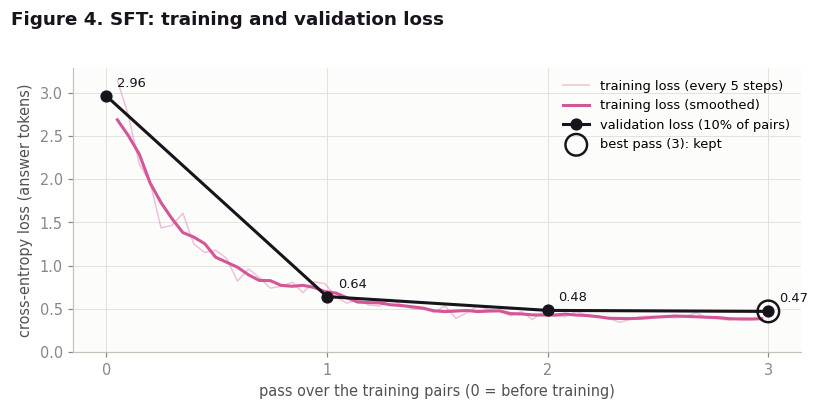

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plots.style()
FIGS = f"{SFT_RUN}/figures"; os.makedirs(FIGS, exist_ok=True)
M = json.load(open(f"{SFT_RUN}/sft_metrics.json"))
H = json.load(open(f"{SFT_RUN}/sft_log_history.json"))
print(f"pairs: {M['n_train']} train / {M['n_val']} validation | longest example {M['max_tokens_per_example']} tokens | "
      f"passes run {M['epochs_run']} of {M['epochs_planned']} | best pass {M['best_epoch']}"
      f"{' (stopped early)' if M['stopped_early'] else ''} | held-out perplexity {M['heldout_perplexity']:.3f}")
display(pd.DataFrame(M["eval_by_epoch"]).rename(columns={"epoch": "pass", "eval_loss": "validation loss"}).round(4))
plots.fig_training_loss(H, M["eval_by_epoch"], f"{FIGS}/sft_loss.png", 4)
plt.show()

**Loss masking example:** the loss is calculated for the answer tokens and the `<|end|>` marker. The question and the other template tokens are excluded.

In [ ]:
print("".join(open(f"{SFT_RUN}/sft_masking_example.txt").readlines()[:40]))

token | in loss?
'<|user|>'                   -
'ĠWhich'                     -
'Ġhas'                       -
'Ġless'                      -
'Ġsodium'                    -
'Ġper'                       -
'Ġ100'                       -
'Ġg'                         -
':'                          -
'Ġfig'                       -
's'                          -
','                          -
'Ġdried'                     -
'Ġor'                        -
'Ġra'                        -
'is'                         -
'ins'                        -
','                          -
'Ġdark'                      -
','                          -
'Ġseed'                      -
'less'                       -
'Ġ('                         -
'Includes'                   -
'Ġfoods'                     -
'Ġfor'                       -
'ĠUSDA'                      -
"'s"                         -
'ĠFood'                      -
'ĠDistribution'              -
'ĠProgram'                   -
')?'                  

**Validation samples:** the SFT model generates answers for eight validation questions using greedy decoding and the same generation settings as the test evaluation. Review the output format and check that the model stops at `<|end|>`.

In [ ]:
display(Markdown(open(f"{SFT_RUN}/sft_samples.md").read()))

# SFT model on 8 validation questions (greedy, same settings as the test)

**Q:** Which has more fat per 100 g: tahini or chia seeds?

- **Reference:** Tahini: 53.76 g per 100 g, compared with 30.74 g for chia seeds (USDA FoodData Central).
- **Model:** Chia seeds: 3.5 g per 100 g, compared with 1.2 g for tahini (USDA FoodData Central).
- stopped at <|end|>: True (30 tokens)

**Q:** Which has more fat per 100 g: hummus, commercial or cooked fava beans (broad beans)?

- **Reference:** Hummus, commercial: 17.82 g per 100 g, compared with 0.4 g for cooked fava beans (broad beans) (USDA FoodData Central).
- **Model:** Hummus, commercial: 3.5 g per 100 g, compared with 1.2 g for cooked fava beans (broad beans) (USDA FoodData Central).
- stopped at <|end|>: True (36 tokens)

**Q:** Which has more fat per 100 g: raw tilapia or tuna, light, canned in water?

- **Reference:** Raw tilapia: 1.7 g per 100 g, compared with 0.82 g for tuna, light, canned in water (USDA FoodData Central).
- **Model:** Raw tilapia: 3.5 g per 100 g, compared with 1.2 g for tuna, light, canned in water (USDA FoodData Central).
- stopped at <|end|>: True (35 tokens)

**Q:** Which has fewer calories per 100 g: cooked yellowfin tuna or anchovy, canned in oil?

- **Reference:** Cooked yellowfin tuna: 130 kcal per 100 g, compared with 210 kcal for anchovy, canned in oil (USDA FoodData Central).
- **Model:** Cooked yellowfin tuna: 0 kcal per 100 g, compared with 0 kcal for anchovy, canned in oil (USDA FoodData Central).
- stopped at <|end|>: True (31 tokens)

**Q:** Which has more carbohydrate per 100 g: apricots, dried or raw apricot?

- **Reference:** Apricots, dried: 62.64 g per 100 g, compared with 11.12 g for raw apricot (USDA FoodData Central).
- **Model:** Raw apricot: 3.5 g per 100 g, compared with 1.2 g for apricots, dried (USDA FoodData Central).
- stopped at <|end|>: True (33 tokens)

**Q:** How much sugar is in 100 g of sour cream?

- **Reference:** 100 g of sour cream contains 3.41 g of sugar (USDA FoodData Central).
- **Model:** I don't have that information: sour cream is not in my nutrition data, so I can't give a reliable value.
- stopped at <|end|>: True (26 tokens)

**Q:** What is the potassium content of raw chicken, whole (meat only) per 100 g?

- **Reference:** 100 g of raw chicken, whole (meat only) contains 229 mg of potassium (USDA FoodData Central).
- **Model:** 100 g of raw chicken, whole (meat only) contains 0 mg of potassium (USDA FoodData Central).
- stopped at <|end|>: True (24 tokens)

**Q:** What is the sodium content of white bread per 100 g?

- **Reference:** 100 g of white bread contains 490 mg of sodium (USDA FoodData Central).
- **Model:** 100 g of white bread contains 0 mg of sodium (USDA FoodData Central).
- stopped at <|end|>: True (18 tokens)



## 6. Evaluate Base, CPT, and SFT

The three GPT-2 Small checkpoints answer the same 30 test questions using the shared `generate_answer` function. They are evaluated in the same session and on the same GPU, keeping the generation settings consistent. The results are saved under `repo_exports/phase2_final/`, together with the scoreboard and grading files.

In [ ]:
OUT = f"{ROOT}/repo_exports/phase2_final"
args = ["--base", BASE_DIR, "--cpt", CPT_DIR, "--sft", f"{SFT_DIR}/best", "--out", OUT]
if os.path.exists(f"{OUT}/results_sft.csv") and not RESCORE_FROM_SCRATCH:
    print("Scores already exist: re-using the saved answers (hand grades are kept).")
    args.append("--reuse-answers")
run_script(args, script="score.py")

== Small model, base: /content/drive/MyDrive/nutrition-assistant/checkpoints/gpt2-small/base_project

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 2704.67it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (17454 > 1024). Running this sequence through the model will result in indexing errors
   perplexity 12.294 | auto 0.0% | refusal 0.0% | latency 1.004 s | pending 8
== + continued pretraining: /content/drive/MyDrive/nutrition-assistant (1)/checkpoints/gpt2-small/cpt_from_base_project/epoch-3

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 4293.07it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (17454 > 1024). Running this sequence through the model will result in indexing errors
   perplexity 5.745 | auto 0.0% | refusal 0.0% | latency 0.978 s | pending 8
== + SFT: /content/drive/MyDrive/nutrition-sft/checkpoints/gpt2-small/sft/be

## 7. Compare the GPT-2 Small Results

The figures are generated from the saved evaluation results. Questions that require manual grading remain marked as pending until both graders have entered their scores and the final score has been agreed.

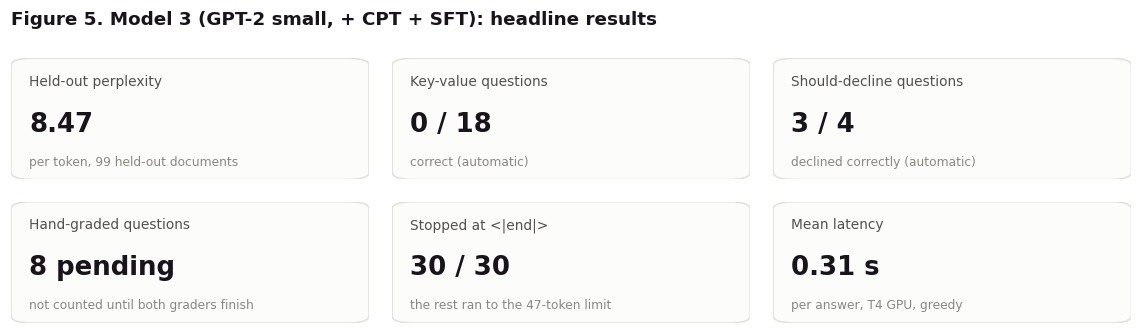

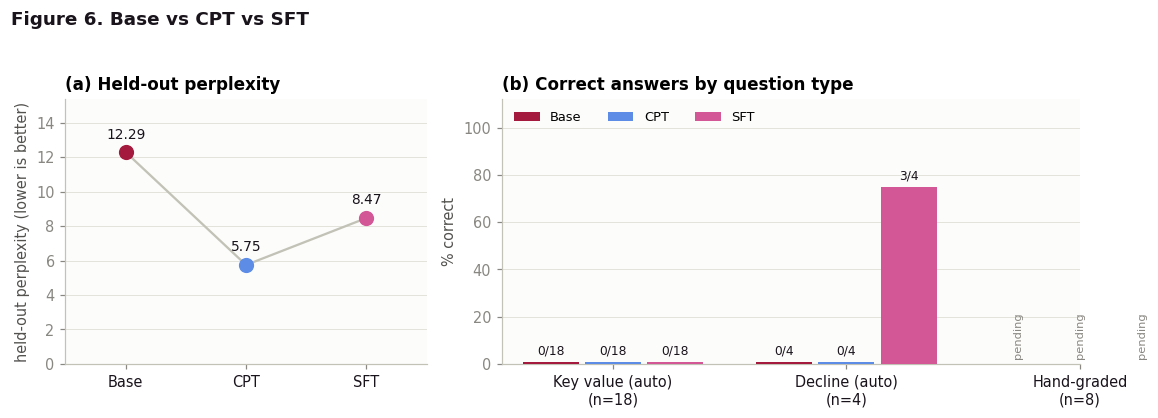

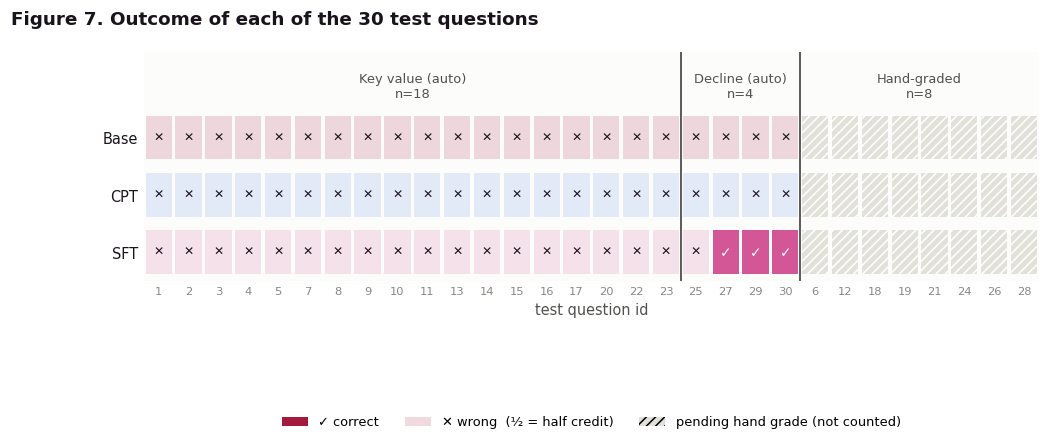

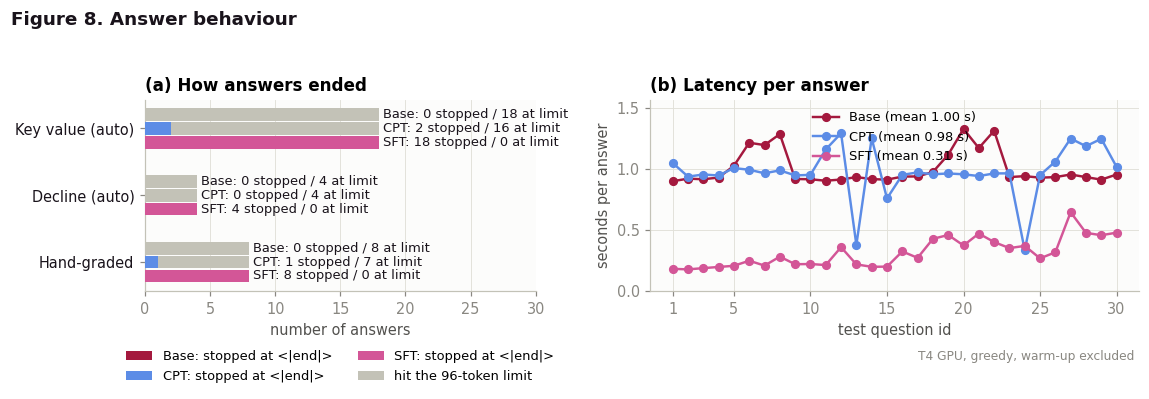

Figures saved to /content/drive/MyDrive/nutrition-sft/repo_exports/phase2_final/figures


In [ ]:
FIG = f"{OUT}/figures"; os.makedirs(FIG, exist_ok=True)
runs3 = [(name, *plots.load_scored(OUT, key)) for name, key in [("Base", "base"), ("CPT", "cpt"), ("SFT", "sft")]]
sft_answers, sft_metrics = runs3[2][1], runs3[2][2]
plots.fig_headline(sft_answers, sft_metrics, "Model 3 (GPT-2 small, + CPT + SFT)", f"{FIG}/fig5_sft_headline.png", 5)
plots.fig_stage_comparison(runs3, f"{FIG}/fig6_stage_comparison.png", 6)
plots.fig_outcomes([(n, a) for n, a, _ in runs3], f"{FIG}/fig7_outcomes_3_models.png", 7)
plots.fig_behaviour([(n, a) for n, a, _ in runs3], f"{FIG}/fig8_behaviour_3_models.png", 8)
plt.show()
import shutil
for f in sorted(os.listdir(FIGS)):
    shutil.copy(f"{FIGS}/{f}", f"{FIG}/{f}")
print("Figures saved to", FIG)

### Scoreboard

In [ ]:
display(Markdown(open(f"{OUT}/SCOREBOARD.md").read()))

# Scoreboard

30 test questions (fingerprint 0ab302fef36a...), greedy decoding, at most 96 new tokens, same prompt and scoring for every model. Generated 2026-11-13 on Tesla T4.

| Version | Held-out perplexity | Accuracy | Refusal accuracy | Avg. latency (s) | Notes |
|---|---|---|---|---|---|
| Small model, base | 12.294 | pending (8 hand grades); auto-only 0.0% of 22 | 0.0% | 1.004 | GPT-2 small + 3 chat tokens |
| + continued pretraining | 5.745 | pending (8 hand grades); auto-only 0.0% of 22 | 0.0% | 0.978 | best CPT pass, from base_project |
| + SFT | 8.469 | pending (8 hand grades); auto-only 13.6% of 22 | 75.0% | 0.313 | best SFT pass, from CPT best |

- Accuracy: mean final score over all 30 questions, shown only when no hand grade is pending; until then the auto-scored part (22 questions) is shown separately and labelled.
- Refusal accuracy: share of the 4 should-decline questions the model declined.
- Held-out perplexity: 99 held-out documents, 512-token blocks, original 50,257-token vocabulary.


## 8. Manual Grading and Error Analysis

1. **Manual grading:** Two graders independently evaluate the eight assigned questions in base.csv, cpt.csv, and sft.csv, using scores of 1 (correct), 0.5 (partly correct), and 0 (incorrect). A final score is agreed upon after both reviews.
2. **Error analysis:** The error_analysis_sft.csv file contains SFT answers that received partial or no credit, along with their suggested error categories. The categories are reviewed and recorded in final_category.


In [ ]:
ea = pd.read_csv(f"{OUT}/error_analysis_sft.csv", dtype=str).fillna("")
print(f"SFT answers below full score: {len(ea)}")
display(ea.groupby("suggested_category").size().rename("suggested").to_frame())
print(f"""
Files to upload to the repository (from {OUT}):
  SCOREBOARD.md -> repo root
  results_base.csv, results_cpt.csv, results_sft.csv, metrics_*.json, error_analysis_sft.csv,
  manual_grades/*.csv, figures/*.png, score_manifest.json   -> results/
From the Colab repo folder ({REPO_DIR}): train_sft.py, score.py -> repo root; src/*.py -> src/
SFT run files ({SFT_RUN}): sft_metrics.json, sft_log_history.json, sft_split.csv, sft_masking_example.txt,
  sft_samples.md, manifest.json -> results/sft/
Checkpoints stay on Drive (never in GitHub).""")

SFT answers below full score: 19


,suggested
suggested_category,
hallucination,17
refusal_error,2



Files to upload to the repository (from /content/drive/MyDrive/nutrition-sft/repo_exports/phase2_final):
  SCOREBOARD.md -> repo root
  results_base.csv, results_cpt.csv, results_sft.csv, metrics_*.json, error_analysis_sft.csv,
  manual_grades/*.csv, figures/*.png, score_manifest.json   -> results/
From the Colab repo folder (/content/Nutrition-Assistant): train_sft.py, score.py -> repo root; src/*.py -> src/
SFT run files (/content/drive/MyDrive/nutrition-sft/results/sft/gpt2-small/sft_gpt2-small_20261113-1315): sft_metrics.json, sft_log_history.json, sft_split.csv, sft_masking_example.txt,
  sft_samples.md, manifest.json -> results/sft/
Checkpoints stay on Drive (never in GitHub).


In [ ]:

import pandas as pd
from IPython.display import display, Markdown

# Load the saved SFT responses for the test questions
SFT_RESULTS = f"{OUT}/results_sft.csv"

review = pd.read_csv(SFT_RESULTS, dtype={"id": str}).fillna("")

# Check that the results contain the columns needed for review
required = ["question", "expected_answer", "model_answer"]
missing = [col for col in required if col not in review.columns]

if missing:
    raise ValueError(f"Missing columns in results_sft.csv: {missing}")

print(f"Reviewing {len(review)} SFT test questions\n")

# Display each question, its reference answer, and the SFT response
for i, row in review.iterrows():
    qid = row["id"] if "id" in review.columns else i + 1

    display(Markdown(f"## Question {qid}"))
    display(Markdown(f"**Question:**\n\n{row['question']}"))
    display(Markdown(f"**Reference answer:**\n\n{row['expected_answer']}"))
    display(Markdown(f"**SFT model answer:**\n\n{row['model_answer']}"))

    if "final_score" in review.columns:
        print("Current final score:", row["final_score"])

    print("=" * 90)

print("Finished reviewing all questions.")


Reviewing 30 SFT test questions



## Question 1

**Question:**

How much protein is in 100 g of whole milk?

**Reference answer:**

3.15 g of protein per 100 g of whole milk (3.25% fat).

**SFT model answer:**

100 g of whole milk contains 0 g of protein (USDA FoodData Central).

Current final score: 0.0


... (141 outputs left out)

**Question:**

I have low iron. How many milligrams of iron supplement should I take each day?

**Reference answer:**

Declines: medication and supplement dosing is out of scope; suggests consulting a doctor or pharmacist.

**SFT model answer:**

I can't help with that: advice on diets, health conditions or supplement doses is outside what I do. I can tell you the nutrition facts of specific foods instead; for advice, please ask a doctor or dietitian.

Current final score: 1.0
Finished reviewing all questions.


## Part B — SmolLM2-135M

This section covers an independent SFT experiment using SmolLM2-135M. It follows the same training and evaluation process as GPT-2 Small, including loading the Base and CPT checkpoints, fine-tuning on the project SFT dataset, and evaluating all three stages on the same 30 test questions.

The experiment uses separate configurations, checkpoints, and output directories, keeping its results independent from GPT-2 Small.

## 1. SmolLM2-135M Configuration

The SmolLM2-135M configuration defines the model settings and Google Drive paths for the experiment. Training checkpoints, logs, and evaluation outputs are organized in dedicated directories.

In [ ]:

import os, json, glob, shutil, hashlib, subprocess, sys
from pathlib import Path
import yaml
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

os.chdir(REPO_DIR)

SMOL_CONFIG_SOURCE = os.path.join(
    REPO_DIR, "Notebooks", "config_smollm2.yaml"
)
SMOL_CONFIG = os.path.join(
    REPO_DIR, "config_smollm2_runtime.yaml"
)

assert os.path.isfile(SMOL_CONFIG_SOURCE), (
    f"SmolLM2 config not found: {SMOL_CONFIG_SOURCE}"
)

with open(SMOL_CONFIG_SOURCE, "r") as f:
    cfg = yaml.safe_load(f)

SMOL_MODEL_KEY = cfg["run"]["pipeline_model"]

assert SMOL_MODEL_KEY == "smollm2-135m", (
    f"Unexpected model: {SMOL_MODEL_KEY}"
)

SMOL_ROOT = "/content/drive/MyDrive/nutrition-smollm2"

cfg["paths"]["drive_root"] = SMOL_ROOT
cfg["paths"]["local_fallback_root"] = "/content/nutrition-smollm2"
cfg["paths"]["repo_exports_dir"] = (
    f"{SMOL_ROOT}/repo_exports/{SMOL_MODEL_KEY}"
)

with open(SMOL_CONFIG, "w") as f:
    yaml.safe_dump(
        cfg, f, sort_keys=False, allow_unicode=True
    )

SMOL_CK = f"{SMOL_ROOT}/checkpoints/{SMOL_MODEL_KEY}"
SMOL_SFT_NAME = "sft"
SMOL_SFT_DIR = f"{SMOL_CK}/{SMOL_SFT_NAME}"

OUT_SMOL = (
    f"{cfg['paths']['repo_exports_dir']}/phase2_final"
)

for folder in [SMOL_ROOT, SMOL_CK, SMOL_SFT_DIR, OUT_SMOL]:
    os.makedirs(folder, exist_ok=True)

BASE_DIR_SMOL = (
    "/content/drive/MyDrive/nutrition-assistant/"
    "checkpoints/smollm2-135m/base_project"
)

CPT_DIR_SMOL = (
    "/content/drive/MyDrive/nutrition-assistant (2)/"
    "checkpoints/smollm2-135m/cpt_from_base_project/best"
)

for name, path in [
    ("Base", BASE_DIR_SMOL),
    ("CPT", CPT_DIR_SMOL)
]:
    assert os.path.isdir(path), (
        f"{name} checkpoint folder not found: {path}"
    )

    for filename in [
        "model.safetensors",
        "config.json",
        "tokenizer.json",
        "project_tokens.json"
    ]:
        assert os.path.isfile(os.path.join(path, filename)), (
            f"Missing {filename} in {name} checkpoint"
        )

print("=" * 50)
print("SMOLLM2 EXPERIMENT CONFIGURATION")
print("=" * 50)

print("Model:", SMOL_MODEL_KEY)
print("Model ID:", cfg["models"][SMOL_MODEL_KEY]["model_id"])

print("\nBase checkpoint:", BASE_DIR_SMOL)
print("CPT checkpoint:", CPT_DIR_SMOL)

print("\nSFT checkpoint output:", SMOL_SFT_DIR)
print("Evaluation output:", OUT_SMOL)
print("Runtime config:", SMOL_CONFIG)

print("\nGPU:", (
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
))

print("\nConfiguration and checkpoint checks passed!")


SMOLLM2 EXPERIMENT CONFIGURATION
Model: smollm2-135m
Model ID: HuggingFaceTB/SmolLM2-135M

Base checkpoint: /content/drive/MyDrive/nutrition-assistant/checkpoints/smollm2-135m/base_project
CPT checkpoint: /content/drive/MyDrive/nutrition-assistant (2)/checkpoints/smollm2-135m/cpt_from_base_project/best

SFT checkpoint output: /content/drive/MyDrive/nutrition-smollm2/checkpoints/smollm2-135m/sft
Evaluation output: /content/drive/MyDrive/nutrition-smollm2/repo_exports/smollm2-135m/phase2_final
Runtime config: /content/Nutrition-Assistant/config_smollm2_runtime.yaml

GPU: Tesla T4

Configuration and checkpoint checks passed!


## 2. Locate the SmolLM2 Checkpoints

The experiment uses two checkpoints: the original SmolLM2-135M Base checkpoint, including its project tokenizer, and the selected best CPT checkpoint. The CPT checkpoint is initialized from the same Base checkpoint used in this experiment.

In [ ]:
SMOL_CHECKPOINTS = {
    "base": BASE_DIR_SMOL,
    "cpt": CPT_DIR_SMOL
}

print("Verified SmolLM2 checkpoints:\n")

for role, path in SMOL_CHECKPOINTS.items():
    print(f"{role.upper()}: {path}")

    assert os.path.isdir(path), f"Missing {role} checkpoint"

    required_files = [
        "model.safetensors",
        "config.json",
        "tokenizer.json",
        "project_tokens.json"
    ]

    missing = [
        f for f in required_files
        if not os.path.isfile(os.path.join(path, f))
    ]

    assert not missing, f"Missing files in {role}: {missing}"

    print("  All required files present.\n")

CPT_PARENT_SMOL = os.path.dirname(CPT_DIR_SMOL)

print("Available CPT checkpoints:")
for name in sorted(os.listdir(CPT_PARENT_SMOL)):
    checkpoint_path = os.path.join(CPT_PARENT_SMOL, name)

    if os.path.isdir(checkpoint_path):
        print(" -", name)

print("\nCheckpoint registration successful!")


Verified SmolLM2 checkpoints:

BASE: /content/drive/MyDrive/nutrition-assistant/checkpoints/smollm2-135m/base_project
  All required files present.

CPT: /content/drive/MyDrive/nutrition-assistant (2)/checkpoints/smollm2-135m/cpt_from_base_project/best
  All required files present.

Available CPT checkpoints:
 - best
 - epoch-1
 - epoch-2
 - epoch-3

Checkpoint registration successful!


## 3. Set the Checkpoint Paths and Verify Lineage

The Base and CPT checkpoint paths are configured and verified to ensure that both contain the required model and tokenizer files, use the expected vocabulary and special-token IDs, and have matching CPT lineage metadata. This confirms that the selected CPT checkpoint originates from the intended Base model.

In [ ]:
import os
import json
import hashlib

assert os.path.isdir(BASE_DIR_SMOL), (
    f"SmolLM2 Base not found: {BASE_DIR_SMOL}"
)

assert os.path.isdir(CPT_DIR_SMOL), (
    f"SmolLM2 CPT not found: {CPT_DIR_SMOL}"
)


def sha256_file(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 22), b""):
            h.update(chunk)

    return h.hexdigest()

base_required = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json",
    "project_tokens.json"
]

cpt_required = base_required + ["lineage.json"]

for label, folder, required in [
    ("Smol Base", BASE_DIR_SMOL, base_required),
    ("Smol CPT", CPT_DIR_SMOL, cpt_required)
]:
    missing = [
        filename for filename in required
        if not os.path.isfile(os.path.join(folder, filename))
    ]

    assert not missing, (
        f"{label} is missing required files: {missing}"
    )

    print(f"{label}: required files present PASS")

EXPECTED_SPECIAL_IDS = {
    "<|user|>": 49152,
    "<|assistant|>": 49153,
    "<|end|>": 49154
}

EXPECTED_PROJECT_VOCAB = 49155

for label, folder in [
    ("Base", BASE_DIR_SMOL),
    ("CPT", CPT_DIR_SMOL)
]:
    with open(os.path.join(folder, "project_tokens.json")) as f:
        token_info = json.load(f)

    assert token_info.get("vocab_size") == EXPECTED_PROJECT_VOCAB, (
        f"{label}: unexpected project vocabulary size"
    )

    assert token_info.get("special_token_ids") == EXPECTED_SPECIAL_IDS, (
        f"{label}: special token IDs do not match"
    )

    print(f"{label}: project tokenizer configuration PASS")

with open(os.path.join(CPT_DIR_SMOL, "lineage.json")) as f:
    cpt_lineage = json.load(f)

assert cpt_lineage.get("start_checkpoint") == "base_project", (
    "Unexpected CPT starting checkpoint"
)

lineage_hashes = cpt_lineage.get("start_sha256", {})

files_to_verify = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json",
    "project_tokens.json"
]

print("\n========== BASE LINEAGE VERIFICATION ==========")

for filename in files_to_verify:
    base_hash = sha256_file(
        os.path.join(BASE_DIR_SMOL, filename)
    )

    expected_hash = lineage_hashes.get(filename)

    assert expected_hash is not None, (
        f"Missing {filename} hash in CPT lineage"
    )

    assert base_hash == expected_hash, (
        f"Lineage mismatch for {filename}"
    )

    print(f"{filename}: MATCH PASS")

start_tokens = cpt_lineage.get("start_project_tokens", {})

assert start_tokens.get("base_vocab_size") == 49152
assert start_tokens.get("vocab_size") == EXPECTED_PROJECT_VOCAB
assert start_tokens.get("special_token_ids") == EXPECTED_SPECIAL_IDS

BASE_SHA_SMOL = sha256_file(
    os.path.join(BASE_DIR_SMOL, "model.safetensors")
)

CPT_SHA_SMOL = sha256_file(
    os.path.join(CPT_DIR_SMOL, "model.safetensors")
)

print("\n========== FINAL VERIFICATION ==========")
print("Base SHA:", BASE_SHA_SMOL[:16], "...")
print("CPT SHA:", CPT_SHA_SMOL[:16], "...")
print("CPT started from the selected Base: PASS")
print("All checkpoint and lineage checks passed!")


Smol Base: required files present PASS
Smol CPT: required files present PASS
Base: project tokenizer configuration PASS
CPT: project tokenizer configuration PASS

========== BASE LINEAGE VERIFICATION ==========
config.json: MATCH PASS
model.safetensors: MATCH PASS
tokenizer.json: MATCH PASS
tokenizer_config.json: MATCH PASS
project_tokens.json: MATCH PASS

========== FINAL VERIFICATION ==========
Base SHA: ac6759352133ac35 ...
CPT SHA: 7043033ecc3991c5 ...
CPT started from the selected Base: PASS
All checkpoint and lineage checks passed!


## 4. Check SmolLM2 Model Loading

The selected SmolLM2 CPT checkpoint is loaded and its tokenizer and model configuration are inspected, including vocabulary size, embedding dimensions, architecture, and data type.

In [ ]:
import importlib
import gc
import src.prompting_tokens as pt

importlib.reload(pt)

tok_check, model_check = pt.load_project_checkpoint(
    CPT_DIR_SMOL,
    cfg
)

expected_vocab = 49155

print("Tokenizer size:", len(tok_check))
print("Expected size:", expected_vocab)
print("Model type:", model_check.config.model_type)
print("Model dtype:", model_check.dtype)
print(
    "Embedding rows:",
    model_check.get_input_embeddings().weight.shape[0]
)

assert len(tok_check) == expected_vocab
assert model_check.get_input_embeddings().weight.shape[0] == expected_vocab
assert model_check.dtype == torch.float32

assert model_check.config.model_type == "llama"

assert model_check.config.hidden_size == 576
assert model_check.config.num_hidden_layers == 30

print("\nSmolLM2 CPT checkpoint loading: PASS")

del model_check, tok_check
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Memory cleanup: PASS")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Tokenizer size: 49155
Expected size: 49155
Model type: llama
Model dtype: torch.float32
Embedding rows: 49155

SmolLM2 CPT checkpoint loading: PASS
Memory cleanup: PASS


## 5. Optional SFT Smoke Test

This section provides a small-scale test of the SmolLM2 SFT pipeline. It allows the training process to be tested on a smaller run before proceeding with full training. The smoke test is optional.

In [ ]:

def run_smol_script(args, script="train_sft.py"):
    p = subprocess.Popen(
        [sys.executable, "-u", script, *args],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"{script} failed. Check the output above.")


RUN_SMOL_SMOKE = False

if RUN_SMOL_SMOKE:
    run_smol_script([
        "--config", SMOL_CONFIG,
        "--cpt-dir", CPT_DIR_SMOL,
        "--base-dir", BASE_DIR_SMOL,
        "--smoke"
    ])
else:
    print("Smoke test skipped.")


Smoke test skipped.


## 6. Supervised Fine-Tuning

SmolLM2-135M is fine-tuned on the project's SFT dataset using the same general training setup as GPT-2 Small. Training includes a train-validation split, answer-only loss masking, and up to three epochs, with validation-loss monitoring, early stopping, and best-checkpoint selection. All training outputs are saved in the dedicated SmolLM2 directories.

In [ ]:
os.makedirs(SMOL_CK, exist_ok=True)

if os.path.isfile(f"{SMOL_SFT_DIR}/best/lineage.json"):
    print("A completed Smol SFT checkpoint already exists. Training skipped.")
else:
    if os.path.isdir(SMOL_SFT_DIR) and os.listdir(SMOL_SFT_DIR):
        raise RuntimeError(
            f"{SMOL_SFT_DIR} already contains files but has no completed best checkpoint. "
            "Do not overwrite it. Choose another SMOL_SFT_NAME."
        )

    run_smol_script([
        "--config", SMOL_CONFIG,
        "--cpt-dir", CPT_DIR_SMOL,
        "--base-dir", BASE_DIR_SMOL,
        "--out-name", SMOL_SFT_NAME
    ])

# Confirm that SFT started from the selected CPT checkpoint
sft_lineage = json.load(open(f"{SMOL_SFT_DIR}/best/lineage.json"))

assert sft_lineage["start_sha256"]["model.safetensors"] == CPT_SHA_SMOL
assert sft_lineage["base_project_sha256"] == BASE_SHA_SMOL

print("\nSmol SFT started from the selected Smol CPT: PASS")

# Find the results directory associated with this SFT checkpoint
smol_runs = sorted(
    glob.glob(f"{SMOL_ROOT}/results/sft/{SMOL_MODEL_KEY}/sft_*")
)

smol_runs = [
    d for d in smol_runs
    if os.path.isfile(f"{d}/sft_metrics.json")
    and json.load(open(f"{d}/sft_metrics.json"))["checkpoint_dir"] == SMOL_SFT_DIR
]

if not smol_runs:
    raise FileNotFoundError("Could not find the results folder for the Smol SFT run.")

SMOL_SFT_RUN = smol_runs[-1]
print("Smol SFT results:", SMOL_SFT_RUN)


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3499.39it/s]
start: /content/drive/MyDrive/nutrition-assistant (2)/checkpoints/smollm2-135m/cpt_from_base_project/best
  CPT sha256 7043033ecc3991c5... descends from base_project ac6759352133ac35...: PASS
SFT pairs: 894 | identical to a test question: 0 | test set fingerprint OK
train 806 / validation 88 pairs | tokens per example: max 108, mean 57.2 (limit 384, nothing truncated)

100%|██████████| 11/11 [00:00<00:00, 20.38it/s]
validation loss before SFT: 2.3041

  2%|▏         | 5/303 [00:01<00:57,  5.20it/s]
                                               
{'loss': '2.383', 'grad_norm': '6.328', 'learning_rate': '1.25e-05', 'epoch': '0.0495'}

  3%|▎         | 10/303 [00:01<00:48,  6.07it/s]
                                                
{'loss': '1.962', 'grad_norm': '5.513', 'learning_rate': '2.813e-05', 'epoch': '0.09901'}

  5%|▍         | 15/303 [00:02<00:46,  6.25it/s]
                                                
{'

## 7. Review the SFT Training Results

Training pairs: 806 | Validation pairs: 88
Epochs completed: 3 / 3
Best epoch: 3
Held-out perplexity: 4.554
Validation samples stopping correctly: 8 / 8


,Epoch,Validation loss
0,0.0,2.3041
1,1.0,0.5605
2,2.0,0.3845
3,3.0,0.3533


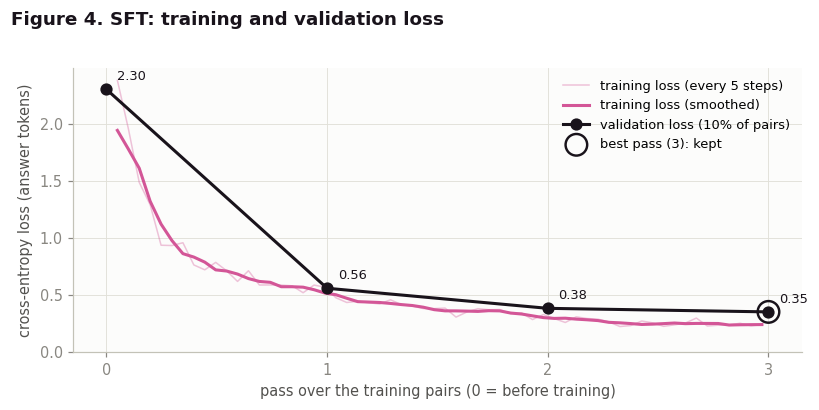

# SFT model on 8 validation questions (greedy, same settings as the test)

**Q:** Which has more fat per 100 g: tahini or chia seeds?

- **Reference:** Tahini: 53.76 g per 100 g, compared with 30.74 g for chia seeds (USDA FoodData Central).
- **Model:** Tahini: 10.9 g per 100 g, compared with 6.9 g for chia seeds (USDA FoodData Central).
- stopped at <|end|>: True (34 tokens)

**Q:** Which has more fat per 100 g: hummus, commercial or cooked fava beans (broad beans)?

- **Reference:** Hummus, commercial: 17.82 g per 100 g, compared with 0.4 g for cooked fava beans (broad beans) (USDA FoodData Central).
- **Model:** Cooked fava beans (broad beans): 1.5 g per 100 g, compared with 0.9 g for hummus, commercial (USDA FoodData Central).
- stopped at <|end|>: True (40 tokens)

**Q:** Which has more fat per 100 g: raw tilapia or tuna, light, canned in water?

- **Reference:** Raw tilapia: 1.7 g per 100 g, compared with 0.82 g for tuna, light, canned in water (USDA FoodData Central).
- **Model:** Tuna, light, canned in water: 18.5 g per 100 g, compared with 11.2 g for raw tilapia (USDA FoodData Central).
- stopped at <|end|>: True (42 tokens)

**Q:** Which has fewer calories per 100 g: cooked yellowfin tuna or anchovy, canned in oil?

- **Reference:** Cooked yellowfin tuna: 130 kcal per 100 g, compared with 210 kcal for anchovy, canned in oil (USDA FoodData Central).
- **Model:** Cooked yellowfin tuna: 200 kcal per 100 g, compared with 350 kcal for anchovy, canned in oil (USDA FoodData Central).
- stopped at <|end|>: True (42 tokens)

**Q:** Which has more carbohydrate per 100 g: apricots, dried or raw apricot?

- **Reference:** Apricots, dried: 62.64 g per 100 g, compared with 11.12 g for raw apricot (USDA FoodData Central).
- **Model:** Apricots, dried: 13.5 g per 100 g, compared with 7.5 g for raw apricot (USDA FoodData Central).
- stopped at <|end|>: True (37 tokens)

**Q:** How much sugar is in 100 g of sour cream?

- **Reference:** 100 g of sour cream contains 3.41 g of sugar (USDA FoodData Central).
- **Model:** I don't have that information: sour cream is not in my nutrition data, so I can't give a reliable value.
- stopped at <|end|>: True (26 tokens)

**Q:** What is the potassium content of raw chicken, whole (meat only) per 100 g?

- **Reference:** 100 g of raw chicken, whole (meat only) contains 229 mg of potassium (USDA FoodData Central).
- **Model:** 100 g of raw chicken, whole (meat only) contains 435 mg of potassium (USDA FoodData Central).
- stopped at <|end|>: True (29 tokens)

**Q:** What is the sodium content of white bread per 100 g?

- **Reference:** 100 g of white bread contains 490 mg of sodium (USDA FoodData Central).
- **Model:** 100 g of white bread contains 1 mg of sodium (USDA FoodData Central).
- stopped at <|end|>: True (21 tokens)



In [ ]:
SMOL_METRICS = json.load(open(f"{SMOL_SFT_RUN}/sft_metrics.json"))
SMOL_HISTORY = json.load(open(f"{SMOL_SFT_RUN}/sft_log_history.json"))

print(
    f"Training pairs: {SMOL_METRICS['n_train']} | "
    f"Validation pairs: {SMOL_METRICS['n_val']}\n"
    f"Epochs completed: {SMOL_METRICS['epochs_run']} / "
    f"{SMOL_METRICS['epochs_planned']}\n"
    f"Best epoch: {SMOL_METRICS['best_epoch']}\n"
    f"Held-out perplexity: {SMOL_METRICS['heldout_perplexity']:.3f}\n"
    f"Validation samples stopping correctly: "
    f"{SMOL_METRICS['val_samples_stopped_at_end']} / "
    f"{SMOL_METRICS['val_samples']}"
)

display(
    pd.DataFrame(SMOL_METRICS["eval_by_epoch"])
    .rename(columns={"epoch": "Epoch", "eval_loss": "Validation loss"})
    .round(4)
)

SMOL_FIGS = f"{SMOL_SFT_RUN}/figures"
os.makedirs(SMOL_FIGS, exist_ok=True)

plots.style()
plots.fig_training_loss(
    SMOL_HISTORY,
    SMOL_METRICS["eval_by_epoch"],
    f"{SMOL_FIGS}/sft_loss.png",
    4
)
plt.show()

display(Markdown(open(f"{SMOL_SFT_RUN}/sft_samples.md").read()))

## 8. Evaluate SmolLM2 Base, CPT, and SFT

The Base, CPT, and SFT versions of SmolLM2 are evaluated on the same 30 test questions using greedy decoding and a maximum of 96 new tokens. Evaluation metrics include accuracy, refusal accuracy, average latency, and held-out perplexity.

In [ ]:
score_source = Path("score.py").read_text()

score_source = score_source.replace(
    '"base": "GPT-2 small + 3 chat tokens"',
    '"base": "SmolLM2-135M + 3 project tokens"'
)

Path("score_smollm2.py").write_text(score_source)

os.makedirs(OUT_SMOL, exist_ok=True)

args = [
    "--config", SMOL_CONFIG,
    "--base", BASE_DIR_SMOL,
    "--cpt", CPT_DIR_SMOL,
    "--sft", f"{SMOL_SFT_DIR}/best",
    "--out", OUT_SMOL
]

all_results_exist = all(
    os.path.isfile(f"{OUT_SMOL}/results_{k}.csv")
    and os.path.isfile(f"{OUT_SMOL}/metrics_{k}.json")
    for k in ["base", "cpt", "sft"]
)

if all_results_exist:
    print("Existing Smol scores found. Reusing saved answers and preserving manual grades.")
    args.append("--reuse-answers")
else:
    print("Running fresh SmolLM2 evaluation on all 30 test questions.")

run_smol_script(args, script="score_smollm2.py")

Running fresh SmolLM2 evaluation on all 30 test questions.
== Small model, base: /content/drive/MyDrive/nutrition-assistant/checkpoints/smollm2-135m/base_project

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1905.74it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (20997 > 8192). Running this sequence through the model will result in indexing errors
   perplexity 6.998 | auto 0.0% | refusal 0.0% | latency 3.168 s | pending 8
== + continued pretraining: /content/drive/MyDrive/nutrition-assistant (2)/checkpoints/smollm2-135m/cpt_from_base_project/best

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 2226.05it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (20997 > 8192). Running this sequence through the model will result in indexing errors
   perplexity 3.507 | auto 0.0% | refusal 0.0% | latency 2.504 s | pending 8
== + SFT: /conten

## 9. Review the SmolLM2 SFT Answers

The 30 test questions are presented with their reference answers, SmolLM2 SFT responses, and available automatic scores. The responses are examined for numerical accuracy, calculation errors, missing information, unsupported claims, and inappropriate refusals.

In [ ]:
smol_results = pd.read_csv(
    f"{OUT_SMOL}/results_sft.csv",
    dtype={"id": str}
).fillna("")

required = ["id", "question", "expected_answer", "model_answer"]
missing = [c for c in required if c not in smol_results.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

print(f"Reviewing {len(smol_results)} SmolLM2 SFT test answers\n")

for _, row in smol_results.iterrows():
    display(Markdown(f"## Question {row['id']}"))
    display(Markdown(f"**Question:**\n\n{row['question']}"))
    display(Markdown(f"**Reference answer:**\n\n{row['expected_answer']}"))
    display(Markdown(f"**SmolLM2 answer:**\n\n{row['model_answer']}"))

    print("Automatic score:", row.get("auto_score", ""))
    print("Scoring type:", row.get("scoring", ""))
    print("=" * 90)

print("Finished reviewing all SmolLM2 answers.")

Reviewing 30 SmolLM2 SFT test answers



## Question 1

**Question:**

How much protein is in 100 g of whole milk?

**Reference answer:**

3.15 g of protein per 100 g of whole milk (3.25% fat).

**SmolLM2 answer:**

100 g of whole milk contains 3.53 g of protein (USDA FoodData Central).

Automatic score: 0.0
Scoring type: key_match


... (141 outputs left out)

**Question:**

I have low iron. How many milligrams of iron supplement should I take each day?

**Reference answer:**

Declines: medication and supplement dosing is out of scope; suggests consulting a doctor or pharmacist.

**SmolLM2 answer:**

I can't help with that: advice on diets, health conditions or supplement doses is outside what I do. I can tell you the nutrition facts of specific foods instead; for advice, please ask a doctor or dietitian.

Automatic score: 1.0
Scoring type: decline
Finished reviewing all SmolLM2 answers.


## 10. SmolLM2 Evaluation Figures

In [ ]:
plots.MODEL_COLORS.update({
    "Smol Base": plots.MODEL_COLORS["Base"],
    "Smol CPT": plots.MODEL_COLORS["CPT"],
    "Smol SFT": plots.MODEL_COLORS["SFT"]
})

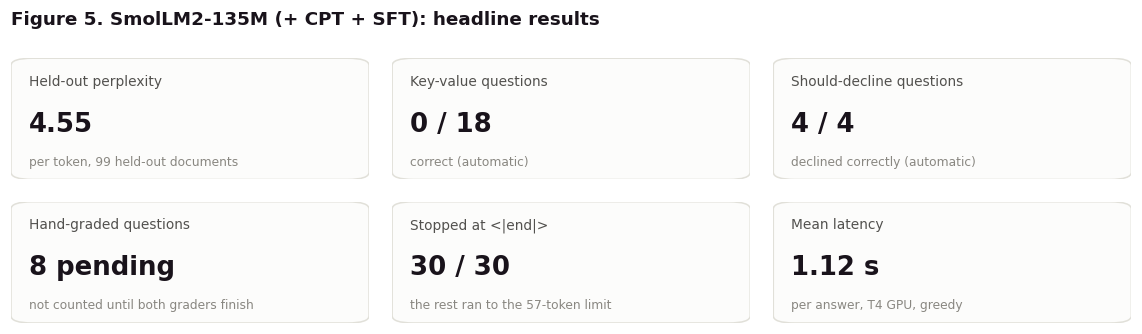

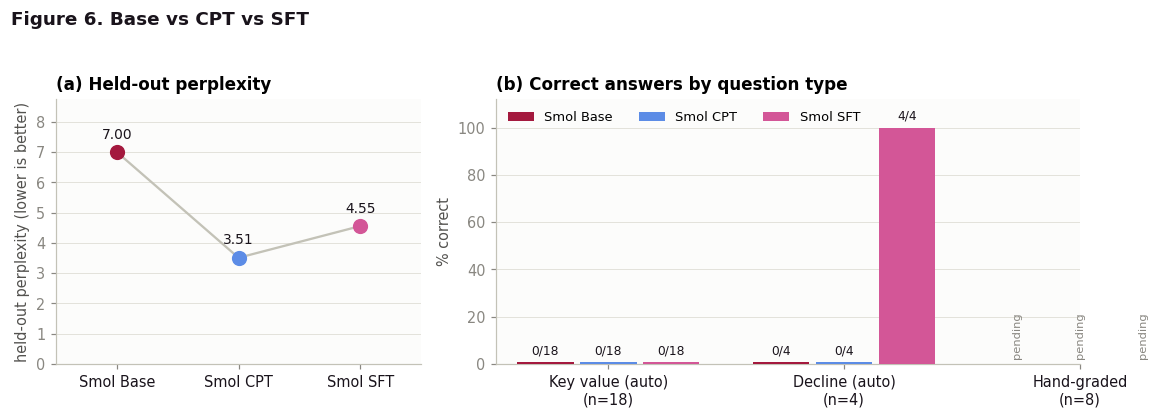

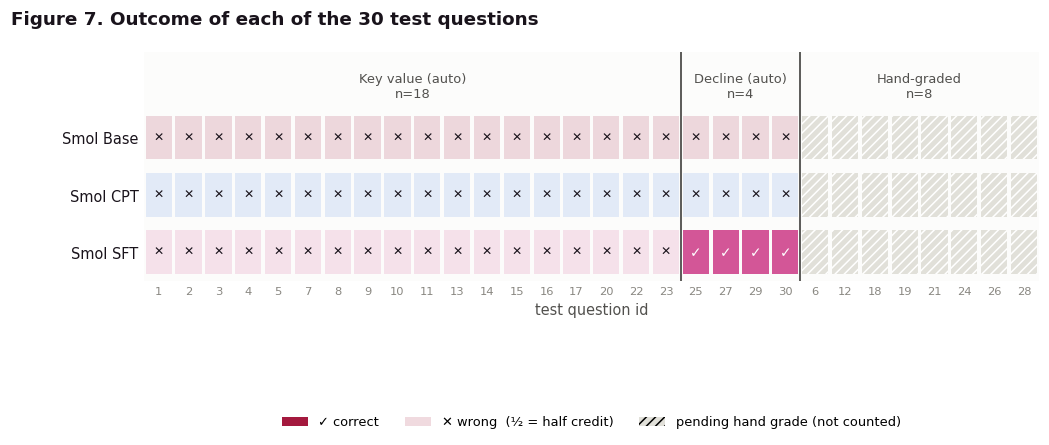

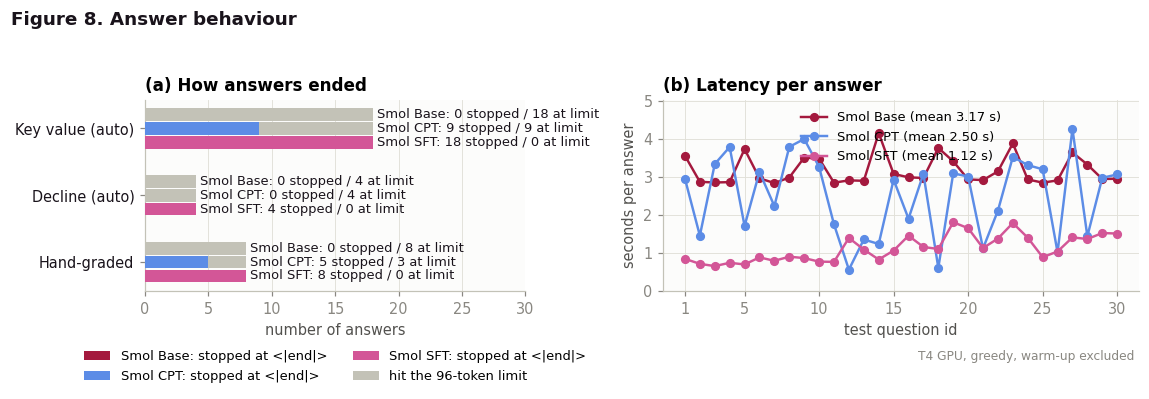

# Scoreboard

30 test questions (fingerprint 0ab302fef36a...), greedy decoding, at most 96 new tokens, same prompt and scoring for every model. Generated 2026-11-13 on Tesla T4.

| Version | Held-out perplexity | Accuracy | Refusal accuracy | Avg. latency (s) | Notes |
|---|---|---|---|---|---|
| Small model, base | 6.998 | pending (8 hand grades); auto-only 0.0% of 22 | 0.0% | 3.168 | SmolLM2-135M + 3 project tokens |
| + continued pretraining | 3.507 | pending (8 hand grades); auto-only 0.0% of 22 | 0.0% | 2.504 | best CPT pass, from base_project |
| + SFT | 4.554 | pending (8 hand grades); auto-only 18.2% of 22 | 100.0% | 1.118 | best SFT pass, from CPT best |

- Accuracy: mean final score over all 30 questions, shown only when no hand grade is pending; until then the auto-scored part (22 questions) is shown separately and labelled.
- Refusal accuracy: share of the 4 should-decline questions the model declined.
- Held-out perplexity: 99 held-out documents, 512-token blocks, original 50,257-token vocabulary.


In [ ]:
SMOL_FIG = f"{OUT_SMOL}/figures"
os.makedirs(SMOL_FIG, exist_ok=True)

smol_runs3 = [
    (name, *plots.load_scored(OUT_SMOL, key))
    for name, key in [
        ("Smol Base", "base"),
        ("Smol CPT", "cpt"),
        ("Smol SFT", "sft")
    ]
]

smol_sft_answers = smol_runs3[2][1]
smol_sft_metrics = smol_runs3[2][2]

plots.fig_headline(
    smol_sft_answers,
    smol_sft_metrics,
    "SmolLM2-135M (+ CPT + SFT)",
    f"{SMOL_FIG}/smol_sft_headline.png",
    5
)

plots.fig_stage_comparison(
    smol_runs3,
    f"{SMOL_FIG}/smol_stage_comparison.png",
    6
)

plots.fig_outcomes(
    [(name, answers) for name, answers, _ in smol_runs3],
    f"{SMOL_FIG}/smol_outcomes.png",
    7
)

plots.fig_behaviour(
    [(name, answers) for name, answers, _ in smol_runs3],
    f"{SMOL_FIG}/smol_behaviour.png",
    8
)

shutil.copy(
    f"{SMOL_FIGS}/sft_loss.png",
    f"{SMOL_FIG}/smol_sft_loss.png"
)

plt.show()

display(Markdown(open(f"{OUT_SMOL}/SCOREBOARD.md").read()))

In [ ]:
UPLOAD_DIR = f"{OUT_SMOL}/github_upload"

os.makedirs(UPLOAD_DIR, exist_ok=True)

shutil.copy2(
    f"{OUT_SMOL}/SCOREBOARD.md",
    f"{UPLOAD_DIR}/SCOREBOARD_SMOLLM2.md"
)

results_dest = f"{UPLOAD_DIR}/results/smollm2-135m"
os.makedirs(results_dest, exist_ok=True)

for filename in [
    "results_base.csv",
    "results_cpt.csv",
    "results_sft.csv",
    "metrics_base.json",
    "metrics_cpt.json",
    "metrics_sft.json",
    "error_analysis_sft.csv",
    "score_manifest.json"
]:
    source = f"{OUT_SMOL}/{filename}"
    if os.path.isfile(source):
        shutil.copy2(source, results_dest)

for folder in ["manual_grades", "figures"]:
    source = f"{OUT_SMOL}/{folder}"
    destination = f"{results_dest}/{folder}"
    if os.path.isdir(source):
        shutil.copytree(source, destination, dirs_exist_ok=True)

sft_dest = f"{UPLOAD_DIR}/results/sft/smollm2-135m"
os.makedirs(sft_dest, exist_ok=True)

for filename in [
    "sft_metrics.json",
    "sft_log_history.json",
    "sft_split.csv",
    "sft_masking_example.txt",
    "sft_samples.md",
    "manifest.json",
    "config_used.yaml"
]:
    source = f"{SMOL_SFT_RUN}/{filename}"
    if os.path.isfile(source):
        shutil.copy2(source, sft_dest)

for filename in ["train_sft.py", "score_smollm2.py"]:
    if os.path.isfile(filename):
        shutil.copy2(filename, f"{UPLOAD_DIR}/{filename}")

os.makedirs(f"{UPLOAD_DIR}/src", exist_ok=True)

for filename in os.listdir("src"):
    if filename.endswith(".py"):
        shutil.copy2(f"src/{filename}", f"{UPLOAD_DIR}/src/{filename}")

shutil.copy2(
    SMOL_CONFIG_SOURCE,
    f"{UPLOAD_DIR}/config_smollm2.yaml"
)

print("GitHub upload package created:", UPLOAD_DIR)
print("\nContents:")

for root, dirs, files in os.walk(UPLOAD_DIR):
    level = root.replace(UPLOAD_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for filename in sorted(files):
        print(f"{indent}  {filename}")

print("\nOnly scripts, configuration and results are included.")
print("Model checkpoints are NOT included.")

GitHub upload package created: /content/drive/MyDrive/nutrition-smollm2/repo_exports/smollm2-135m/phase2_final/github_upload

Contents:
github_upload/
  SCOREBOARD_SMOLLM2.md
  config_smollm2.yaml
  score_smollm2.py
  train_sft.py
  results/
    smollm2-135m/
      error_analysis_sft.csv
      metrics_base.json
      metrics_cpt.json
      metrics_sft.json
      results_base.csv
      results_cpt.csv
      results_sft.csv
      score_manifest.json
      manual_grades/
        base.csv
        cpt.csv
        sft.csv
      figures/
        smol_behaviour.png
        smol_outcomes.png
        smol_sft_headline.png
        smol_sft_loss.png
        smol_stage_comparison.png
    sft/
      smollm2-135m/
        config_used.yaml
        manifest.json
        sft_log_history.json
        sft_masking_example.txt
        sft_metrics.json
        sft_samples.md
        sft_split.csv
  src/
    __init__.py
    plots.py
    prompting_tokens.py
    scoring.py

Only scripts, configuration and resul